# Multifractality, temporal dependence and cooperativity in 50 assets
### Consolidated, reproducible notebook for the *Finance Research Letters* submission

**What this notebook does (one run, top to bottom):**

| § | Content | Replaces / extends |
|---|---------|--------------------|
| 0 | Reproducibility layer: fixed config, seeds, pinned versions, hashed data cache, run metadata | hard-coded `D:\...` paths, un-frozen `END` dates |
| 1 | Data (50 assets 2010–2026, 15-stock DJIA cohort + S&P 500 2003–2026, DJIA/Nasdaq 1990–2024) | all three data scripts |
| 2 | **Vectorised MF-DFA** (verified against your original loop implementation) | `mfdfa` in `dfa_and_its_variants` |
| 3 | **Three-surrogate decomposition of Δα**: shuffle / IAAFT / phase-randomised → fat-tail, linear-correlation and nonlinear-dependence shares | extends the shuffle-only test |
| 4 | Cross-section: Δα by asset class, OLS with robust SEs, half-sample stability, robustness grid | new |
| 5 | **Rolling Δα vs rolling pairwise correlation** across 2008, 2020, 2022; vol-controlled, circular-shift significance | extends the slide |
| 6 | Correlation build-up with proper statistics: block-bootstrap CIs, HAC slope, placebo ranking, heat-maps | fixes the slide |
| 7 | √t scaling → **variance-ratio test** (fixes the mis-labelled "Ratio" column) | `correlation_and_returns` |
| 8 | Paper-numbers JSON, `requirements.txt`, run metadata | new |

**Deliberately excluded:** drawdown (as requested), LPPL fits (all windows flagged "artefact", parameters pinned to bounds) and the Rosenstein-LLE sweep (the lag 7–10 "bump" is inside the ±0.03 noise band). Both are better as future work than as claims.

**Interpretation note.** The shuffle surrogate removes *all* temporal dependence, which includes volatility clustering (a nonlinear dependence), not just linear correlation. Raw-return autocorrelation is ≈0, so most of the former "correlation-driven share" is really *nonlinear* dependence. §3 separates the two; word the paper accordingly.

**How to run.** `pip install -r requirements.txt` (written by §8) → Run All. First run downloads and freezes data into `flr_run/data_cache/` with SHA-256 hashes; later runs reuse the cache and refuse to run if a file was altered. Set `FORCE_REDOWNLOAD=True` only to deliberately refresh.
---
**Revision R1 (this file).** Estimator code now lives in `flr_core.py` (verbatim) and all figure styling in `figstyle.py`; both are imported, nothing is duplicated.
All new analyses are in the cells marked `REVISION` (Gaussian benchmark, ordering of contrasts, CL=F sensitivity, sampling audit, spectrum diagnostics,
half-sample reliability, window-matched rolling test, multiple-testing, trading-day simulation). They use new RNG names, so every previously reported number is
reproduced bit for bit; new tables go to `outputs/revision/`, revised figures to `flr_run/figures/revised/` (PDF + 300 dpi PNG), old figures are left alone.


In [1]:
# ═════════════════════════════ §0  SETUP & REPRODUCIBILITY ═════════════════════════════
import os, sys, json, hashlib, platform, time, zlib, warnings
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import savgol_filter
from scipy.special import logsumexp
from scipy.stats import false_discovery_control
from joblib import Parallel, delayed
import statsmodels.api as sm
import statsmodels.formula.api as smf
from functools import partialmethod
Path.write_text = partialmethod(Path.write_text, encoding="utf-8")   # Windows defaults to cp1252 and can't encode Δ, α, ×, ±
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ── Every tunable lives here. Nothing below hard-codes a path, date or seed. ──
CFG = dict(
    SEED            = 42,
    DATA_MODE       = os.environ.get("FLR_DATA_MODE", "yfinance"),  # "synthetic" = smoke-test ONLY
    FORCE_REDOWNLOAD= False,
    # data windows (END dates are FIXED so reruns see identical samples)
    START_A="2010-01-01", END_A="2026-04-11",     # 50-asset MF-DFA universe
    START_B="2003-01-01", END_B="2026-04-11",     # DJIA cohort + S&P 500 (episodes)
    START_C="1990-01-01", END_C="2024-01-01",     # DJIA / Nasdaq (scaling law)
    # MF-DFA (identical to your original settings)
    Q_VALS=[float(q) for q in range(-30, 31, 5)],
    SCALE_MIN=20, SCALE_MAX=800, N_SCALES=30, POLY_ORD=1, OVERLAP=0.75,
    # surrogates (paper run: 500, as in your original)
    N_SURR=int(os.environ.get("FLR_N_SURR", 500)), IAAFT_ITERS=50, N_JOBS=-1,
    # rolling analysis
    ROLL_WINDOW=1000, ROLL_STEP=20, ROLL_Q=[float(q) for q in range(-10, 11, 2)],
    ROLL_SCALE_MIN=10, ROLL_SCALE_MAX=250, ROLL_N_SCALES=20,
    CORR_WINDOW=60, N_BOOT=int(os.environ.get("FLR_N_BOOT", 1000)), BOOT_BLOCK=5,
    N_PERM=int(os.environ.get("FLR_N_PERM", 2000)),
)
CFG_HASH = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:10]

SYN = CFG["DATA_MODE"] == "synthetic"
BASE   = Path(os.environ.get("FLR_OUT", "flr_run_SYNTHETIC" if SYN else "flr_run"))
CACHE  = BASE / ("data_synthetic" if SYN else "data_cache")
FIGS, TABLES = BASE / "figures", BASE / "tables"
for d in (CACHE, FIGS, TABLES): d.mkdir(parents=True, exist_ok=True)

np.random.seed(CFG["SEED"])                     # legacy global RNG (nothing here relies on it)
ROOT_SS = np.random.SeedSequence(CFG["SEED"])   # every random task gets a spawned child → order-independent
def rng_for(name):
    """Deterministic RNG per named task, independent of execution order / n_jobs."""
    return np.random.default_rng(np.random.SeedSequence([CFG["SEED"], zlib.crc32(name.encode())]))

sys.path.insert(0, str(Path.cwd()))                       # flr_core.py / figstyle.py live next to the notebook
import figstyle; figstyle.apply()                         # ONE shared style for every figure
from figstyle import FIG_W_1COL, FIG_W_2COL
CLASS_COLORS, GROUP_MARKERS, GROUP_ORDER = figstyle.GROUP_COLORS, figstyle.GROUP_MARKERS, figstyle.GROUP_ORDER

# Episode bands: ONE definition used by every figure/table (dates from here, never typed in a plot call)
EPISODE_BANDS = [
    dict(key="GFC",    start="2007-10-09", end="2009-03-09", label="2008-09 GFC",        short="GFC"),
    dict(key="COVID",  start="2020-02-19", end="2020-03-23", label="2020 COVID",         short="COVID"),
    dict(key="BEAR22", start="2022-01-03", end="2022-10-12", label="2022 bear market",   short="2022 bear"),
]
REV = Path(os.environ.get("FLR_REV", "outputs/revision"))      # new results; old outputs stay untouched

TIMINGS = {}
@contextmanager
def timed(name):
    t0 = time.time(); yield
    TIMINGS[name] = round(time.time() - t0, 1); print(f"[{name}] {TIMINGS[name]} s")

FIGS_REV = FIGS / "revised"
def savefig(fig, name):
    """Revised figures only: vector PDF + 300 dpi PNG into figures/revised/ (old PNGs in figures/ are kept)."""
    figstyle.save(fig, Path(name).stem, FIGS_REV); plt.show()

def savetable(df, name, **kw):
    df.to_csv(TABLES / name, **kw); return df

if SYN:
    print("█" * 78 + "\n█  SYNTHETIC SMOKE-TEST MODE — numbers are meaningless, do NOT use in the paper  █\n" + "█" * 78)
print(f"run config hash {CFG_HASH} | python {platform.python_version()} | output → {BASE}")

run config hash 0aaa4807ab | python 3.10.10 | output → flr_run


In [2]:
# ═════════════════════════════ §1  DATA LAYER (cache + SHA-256 manifest) ═════════════════════════════
MANIFEST = CACHE / "manifest.json"

def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()

def _manifest():
    return json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {}

# ---- synthetic generator (smoke tests only; never used unless DATA_MODE == "synthetic") ----
_MASTER = pd.bdate_range("1985-01-01", "2026-12-31")
_SYN_START = {"ETH-USD": "2017-11-09", "META": "2012-05-18"}
def _ar_vol(rng, n, phi=0.98, s=0.15):
    lv = np.zeros(n); e = rng.standard_normal(n)
    for i in range(1, n): lv[i] = phi * lv[i - 1] + s * e[i]
    return np.exp(lv)
_FACTOR = None
def _synth(ticker, start, end):
    global _FACTOR
    if _FACTOR is None:
        r = np.random.default_rng(CFG["SEED"])
        _FACTOR = pd.Series(0.008 * _ar_vol(r, len(_MASTER)) * r.standard_t(4, len(_MASTER)) / np.sqrt(2), index=_MASTER)
    r = np.random.default_rng(CFG["SEED"] + zlib.crc32(ticker.encode()))
    crypto = ticker.endswith("-USD")
    s0 = max(pd.Timestamp(start), pd.Timestamp(_SYN_START.get(ticker, start)))
    idx = pd.date_range(s0, pd.Timestamp(end) - pd.Timedelta(days=1), freq="D" if crypto else "B")
    fac = _FACTOR.reindex(idx).fillna(0.0).values
    idio = 0.010 * _ar_vol(r, len(idx)) * r.standard_t(4, len(idx)) / np.sqrt(2)
    return pd.Series(100 * np.exp(np.cumsum(0.5 * fac + idio)), index=idx, name="Close")

def _download_yf(ticker, start, end):
    import yfinance as yf
    for _ in range(3):
        df = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True, threads=False)
        if df is not None and len(df): break
        time.sleep(2)
    else:
        raise RuntimeError(f"yfinance returned nothing for {ticker}")
    s = df["Close"].squeeze().dropna()
    s.name = "Close"; return s

def _read_cached(fn, ticker):
    return pd.read_csv(fn, index_col=0, parse_dates=True, float_precision="round_trip").iloc[:, 0].rename(ticker)

def get_close(ticker, start, end):
    fn = CACHE / f"{ticker.replace('^','IDX_').replace('=','_')}_{start}_{end}.csv"
    man = _manifest()
    if fn.exists() and not CFG["FORCE_REDOWNLOAD"]:
        if fn.name in man and man[fn.name]["sha256"] != _sha256(fn):
            raise RuntimeError(f"{fn.name}: cached file does not match its recorded SHA-256 — data was modified.")
        return _read_cached(fn, ticker)
    s = _synth(ticker, start, end) if SYN else _download_yf(ticker, start, end)
    s.to_csv(fn, header=["Close"])
    man[fn.name] = dict(sha256=_sha256(fn), rows=len(s), first=str(s.index[0].date()), last=str(s.index[-1].date()),
                        source="synthetic" if SYN else f"yfinance {metadata.version('yfinance')}",
                        downloaded_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"))
    MANIFEST.write_text(json.dumps(man, indent=1, sort_keys=True))
    return _read_cached(fn, ticker)      # ALWAYS re-read from disk so first run == every later run, bit for bit

def get_panel(tickers, start, end):
    return pd.concat([get_close(t, start, end) for t in tickers], axis=1, sort=False)

# ---- universe (same 50 tickers as your DFA notebook) ----
SECTORS_A = {
    "Tech":        ["AAPL","MSFT","GOOG","AMZN","NVDA","META","TSLA","NFLX","AMD","INTC"],
    "Financials":  ["JPM","BAC","GS","MS","WFC","BLK","C","AXP","V","MA"],
    "Health/Cons": ["JNJ","PFE","UNH","MRK","ABBV","PG","KO","PEP","WMT","COST"],
    "Energy/Ind":  ["XOM","CVX","COP","BA","CAT","GE","HON","LMT","RTX","UPS"],
    "Commodities": ["GC=F","SI=F","CL=F"],
    "Crypto":      ["BTC-USD","ETH-USD"],
    "Intl ETFs":   ["EWJ","EWZ","FXI","EWG","EWU"],
}
TICKERS_A = [t for v in SECTORS_A.values() for t in v]
GROUP = {t: {"Tech": "Tech", "Financials": "Financials", "Health/Cons": "Health/Cons", "Energy/Ind": "Energy/Ind",
             "Commodities": "Commodity", "Crypto": "Crypto", "Intl ETFs": "Intl ETF"}[s]
         for s, v in SECTORS_A.items() for t in v}
COHORT = ["MMM","AXP","BA","CAT","CVX","KO","XOM","GE","IBM","MCD","MRK","PG","WMT","JPM","MSFT"]  # 15 stocks, as on the slide

with timed("data download/load"):
    prices_A = get_panel(TICKERS_A, CFG["START_A"], CFG["END_A"])

returns_A, data_notes = {}, []
for t in TICKERS_A:
    p = prices_A[t].dropna()
    bad = int((p <= 0).sum())
    if bad: data_notes.append(f"{t}: {bad} non-positive price(s) dropped before log (e.g. WTI Apr-2020)")
    p = p[p > 0]
    returns_A[t] = np.log(p).diff().dropna()

summary = pd.DataFrame({t: dict(group=GROUP[t], n_returns=len(r), first=r.index[0].date(), last=r.index[-1].date(),
                                ann_vol=r.std() * np.sqrt(252 if GROUP[t] != "Crypto" else 365))
                        for t, r in returns_A.items()}).T
savetable(summary, "data_summary.csv")
print(summary.head(8).to_string()); print("…"); print("\n".join(data_notes) or "no data issues")

[data download/load] 0.3 s
     group n_returns       first        last   ann_vol
AAPL  Tech      4091  2010-01-05  2026-04-10  0.281027
MSFT  Tech      4091  2010-01-05  2026-04-10  0.256168
GOOG  Tech      4091  2010-01-05  2026-04-10  0.275484
AMZN  Tech      4091  2010-01-05  2026-04-10  0.327581
NVDA  Tech      4091  2010-01-05  2026-04-10  0.452708
META  Tech      3492  2012-05-21  2026-04-10  0.397614
TSLA  Tech      3969  2010-06-30  2026-04-10  0.572423
NFLX  Tech      4091  2010-01-05  2026-04-10  0.492176
…
CL=F: 1 non-positive price(s) dropped before log (e.g. WTI Apr-2020)


In [3]:
# ═════════════════════════════ §2  MF-DFA (vectorised) + verification ═════════════════════════════
from flr_core import (mfdfa_fast, spectrum, spectrum_direct, delta_alpha,
                      segment_rms, iaaft, phase_randomise)   # verbatim from the original notebook

def da_of(x, q=None, smin=None, smax=None, ns=None, po=None, ov=None, method="sg"):
    c = CFG
    q = c["Q_VALS"] if q is None else q
    _, _, hq = mfdfa_fast(x, q,
                          c["SCALE_MIN"] if smin is None else smin,
                          c["SCALE_MAX"] if smax is None else smax,
                          c["N_SCALES"]  if ns   is None else ns,
                          c["POLY_ORD"]  if po   is None else po,
                          c["OVERLAP"]   if ov   is None else ov)
    return delta_alpha(q, hq, method), hq

# ---- verification against the ORIGINAL (slow, np.polyfit) implementation ----
def mfdfa_reference(x, q_vals, scale_min, scale_max, n_scales, poly_ord=1, overlap=0.75):
    y = np.cumsum(x - x.mean()); N = len(y)
    scale_max = min(scale_max, N // 4); scale_min = max(scale_min, poly_ord + 2)
    scales = np.unique(np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int))
    scales = scales[scales >= scale_min]
    Fqs = np.full((len(q_vals), len(scales)), np.nan)
    for i, s in enumerate(scales):
        step = max(1, int(s * (1.0 - overlap))); starts = np.arange(0, N - s + 1, step)
        if len(starts) < 4: continue
        t = np.arange(s); rms = []
        for st in starts:
            seg = y[st:st + s]; coef = np.polyfit(t, seg, poly_ord)
            r = np.sqrt(np.mean((seg - np.polyval(coef, t)) ** 2))
            if r > 0: rms.append(r)
        rms = np.asarray(rms)
        for j, q in enumerate(q_vals):
            Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms ** 2))) if q == 0 else (np.mean(rms ** q)) ** (1.0 / q)
    hq = np.full(len(q_vals), np.nan)
    for j in range(len(q_vals)):
        m = np.isfinite(Fqs[j]) & (Fqs[j] > 0)
        if m.sum() >= 4: hq[j] = np.polyfit(np.log(scales[m]), np.log(Fqs[j][m]), 1)[0]
    return scales, Fqs, hq

# Check a short series AND the full-length series (the paper's regime: scale cap 800), on H(q) and on the width
_args = (CFG["Q_VALS"], CFG["SCALE_MIN"], CFG["SCALE_MAX"], CFG["N_SCALES"])
for lab, _x in (("AAPL first 2500", returns_A["AAPL"].values[:2500]), ("AAPL full length", returns_A["AAPL"].values)):
    _, _, h_ref = mfdfa_reference(_x, *_args)
    _, _, h_new = mfdfa_fast(_x, *_args)
    d_ref, d_new = delta_alpha(CFG["Q_VALS"], h_ref), delta_alpha(CFG["Q_VALS"], h_new)
    print(f"{lab:18s} N={len(_x)}: max |H(q)_fast − H(q)_original| = {np.nanmax(np.abs(h_ref - h_new)):.2e} | "
          f"Δα ref {d_ref:.6f} vs fast {d_new:.6f}")
    assert np.allclose(h_ref, h_new, atol=1e-6, equal_nan=True), f"vectorised MF-DFA disagrees with the original ({lab})"
    assert abs(d_ref - d_new) < 1e-6, f"Δα disagrees ({lab})"

da_of(returns_A["AAPL"].values)                                   # warm-up call
t0 = time.perf_counter(); da_of(returns_A["AAPL"].values); print(f"one full-length Δα evaluation: {time.perf_counter() - t0:.3f} s")

AAPL first 2500    N=2500: max |H(q)_fast − H(q)_original| = 4.44e-16 | Δα ref 0.319497 vs fast 0.319497
AAPL full length   N=4091: max |H(q)_fast − H(q)_original| = 2.22e-16 | Δα ref 0.491252 vs fast 0.491252
one full-length Δα evaluation: 0.017 s


In [4]:
# ═════════════════════════════ §3  SURROGATE DECOMPOSITION OF Δα ═════════════════════════════
# shuffle : destroys ALL temporal dependence, keeps the return distribution (fat tails)
# IAAFT   : keeps distribution AND linear autocorrelation, destroys nonlinear dependence (vol clustering)
# phase   : keeps linear autocorrelation only (Gaussianised), destroys distribution + nonlinear dependence
#   Δα_orig = Δα_shuffle                     (distribution / fat tails)
#           + (Δα_IAAFT − Δα_shuffle)        (linear correlation)
#           + (Δα_orig − Δα_IAAFT)           (nonlinear dependence, e.g. volatility clustering)

# iaaft / phase_randomise: imported from flr_core (see section 2)

def surrogate_task(ticker, x, n_surr, iters, cfg):
    """Pure function (picklable, no globals mutated) → deterministic for a given (seed, ticker)."""
    rng = np.random.default_rng(np.random.SeedSequence([cfg["SEED"], zlib.crc32(ticker.encode())]))
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS","SCALE_MIN","SCALE_MAX","N_SCALES","POLY_ORD","OVERLAP"))
    N = len(x)
    def da(z):
        _, _, hq = mfdfa_fast(z, q, smin, smax, ns, po, ov); return delta_alpha(q, hq)
    _, _, h0 = mfdfa_fast(x, q, smin, smax, ns, po, ov)
    d0 = delta_alpha(q, h0); h2 = h0[q.index(2.0)] if 2.0 in q else np.nan
    S = {k: np.full(n_surr, np.nan) for k in ("shuffle", "iaaft", "phase")}
    for i in range(n_surr):
        S["shuffle"][i] = da(rng.permutation(x))
        S["iaaft"][i]   = da(iaaft(x, rng, iters))
        S["phase"][i]   = da(phase_randomise(x, rng))
    row = dict(ticker=ticker, n=N, delta_alpha=d0, H2=h2)
    for k, v in S.items():
        v = v[np.isfinite(v)]
        row[f"{k}_mean"] = v.mean(); row[f"{k}_sd"] = v.std(ddof=1)
        row[f"{k}_p05"], row[f"{k}_p95"] = np.percentile(v, 5), np.percentile(v, 95)   # NEW: for Fig. 3 bars (no RNG use)
        row[f"p_{k}"] = (np.sum(v >= d0) + 1) / (len(v) + 1)       # right-tailed: orig wider than surrogate
    return row

with timed("surrogate decomposition"):
    raw = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(
        delayed(surrogate_task)(t, returns_A[t].values, CFG["N_SURR"], CFG["IAAFT_ITERS"], CFG) for t in TICKERS_A)

res = pd.DataFrame(raw).set_index("ticker").loc[TICKERS_A]
res["group"] = [GROUP[t] for t in res.index]
for k in ("shuffle", "iaaft", "phase"):
    res[f"q_{k}"] = false_discovery_control(res[f"p_{k}"].values, method="bh")      # Benjamini–Hochberg
res["share_fat_tail_pct"]  = 100 * res["shuffle_mean"] / res["delta_alpha"]
res["share_linear_pct"]    = 100 * (res["iaaft_mean"] - res["shuffle_mean"]) / res["delta_alpha"]
res["share_nonlinear_pct"] = 100 * (res["delta_alpha"] - res["iaaft_mean"]) / res["delta_alpha"]
res["share_temporal_pct"]  = 100 * (res["delta_alpha"] - res["shuffle_mean"]) / res["delta_alpha"]   # = your old "corr_share_pct"
savetable(res, "delta_alpha_surrogates.csv")

n = len(res)
print(f"Assets: {n} | surrogates per test: {CFG['N_SURR']}")
for k, lab in (("shuffle", "temporal dependence matters  (orig > shuffle)"),
               ("iaaft",   "nonlinear dependence matters (orig > IAAFT)"),
               ("phase",   "non-Gaussian/nonlinear structure (orig > phase-rand.)")):
    print(f"  BH q<0.05 — {lab:55s}: {(res[f'q_{k}'] < .05).sum():>2d}/{n}")
print("\nMean / median share of Δα (%):")
print(res[["share_fat_tail_pct", "share_linear_pct", "share_nonlinear_pct", "share_temporal_pct"]].agg(["mean", "median"]).round(1).to_string())
print("\nΔα by asset class:"); print(res.groupby("group")["delta_alpha"].agg(["count", "mean", "min", "max"]).round(3).to_string())

[surrogate decomposition] 271.8 s
Assets: 50 | surrogates per test: 500
  BH q<0.05 — temporal dependence matters  (orig > shuffle)          : 36/50
  BH q<0.05 — nonlinear dependence matters (orig > IAAFT)            : 34/50
  BH q<0.05 — non-Gaussian/nonlinear structure (orig > phase-rand.)  : 49/50

Mean / median share of Δα (%):
        share_fat_tail_pct  share_linear_pct  share_nonlinear_pct  share_temporal_pct
mean                  73.0               0.7                 26.3                27.0
median                66.5               2.5                 32.6                33.5

Δα by asset class:
             count   mean    min    max
group                                  
Commodity        3  0.569  0.511  0.666
Crypto           2  0.590  0.580  0.600
Energy/Ind      10  0.616  0.445  0.693
Financials      10  0.521  0.343  0.637
Health/Cons     10  0.596  0.419  0.824
Intl ETF         5  0.615  0.485  0.681
Tech            10  0.412  0.181  0.537


In [5]:
res["group"] = [GROUP[t] for t in res.index]
if "res_x" in globals(): res_x["group"] = [GROUP[t] for t in res_x.index]

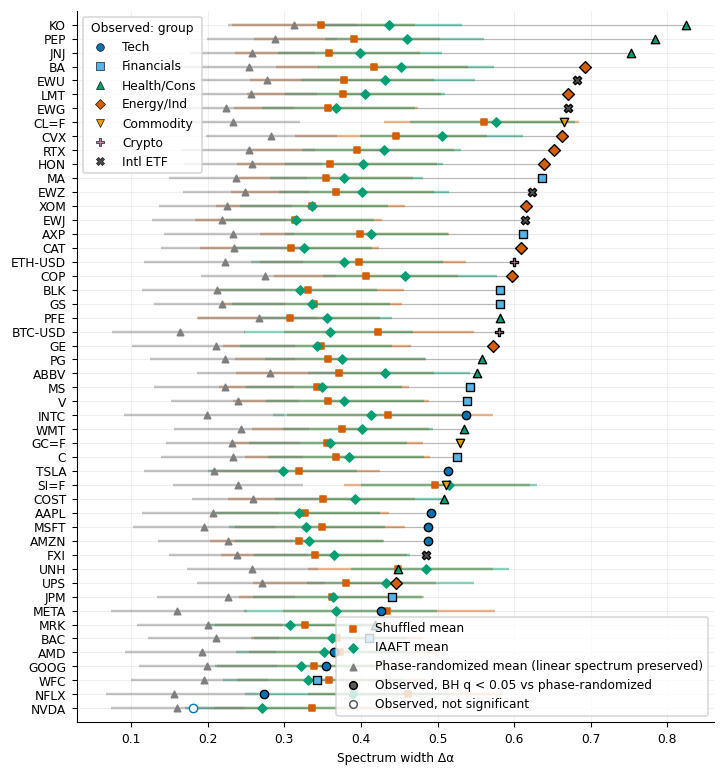

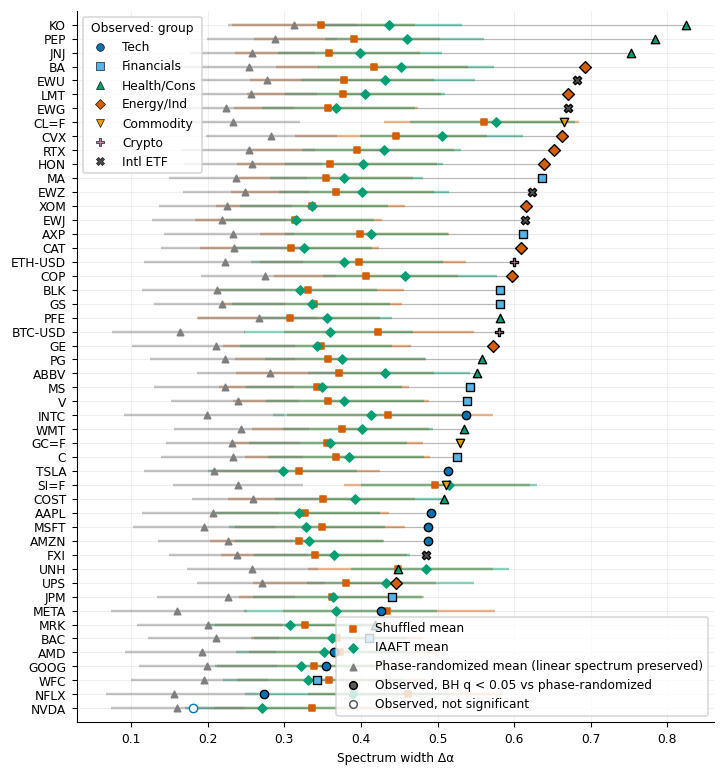

In [6]:
# ── Fig. 3 (paper): observed width vs surrogate means per asset, sorted by observed width ──
# Filled observed marker = BH-significant (q < 0.05) against the phase-randomized benchmark (saved q_phase); hollow = not significant.
# Horizontal 5th-95th percentile bars need per-surrogate widths; they are drawn from the saved *_p05 / *_p95 columns when present.
def plot_surrogate_means(res, name="fig3_surrogate_means"):
    o = res.sort_values("delta_alpha"); y = np.arange(len(o))
    fig, ax = plt.subplots(figsize=(FIG_W_2COL, 8.4))
    ax.hlines(y, o["shuffle_mean"], o["delta_alpha"], color="#bbbbbb", lw=.8, zorder=1)
    have_pct = all(f"{k}_p05" in o.columns for k in ("shuffle", "iaaft", "phase"))
    if not have_pct: print("[Fig. 3] per-surrogate percentiles are not in this results table -> bars skipped (rerun section 3 to add them)")
    names = {"shuffle": "Shuffled mean", "iaaft": "IAAFT mean", "phase": "Phase-randomized mean (linear spectrum preserved)"}
    for k in ("shuffle", "iaaft", "phase"):
        st = figstyle.SURR_STYLE[k]
        if have_pct: ax.hlines(y, o[f"{k}_p05"], o[f"{k}_p95"], color=st["c"], lw=1.6, alpha=.45, zorder=2)
        ax.scatter(o[f"{k}_mean"], y, s=18, marker=st["marker"], c=st["c"], label=names[k], zorder=3)
    sig = (o["q_phase"] < .05).values
    for g in GROUP_ORDER:
        for flag in (True, False):
            m = (o["group"] == g).values & (sig == flag)
            if m.any():
                ax.scatter(o.loc[m, "delta_alpha"], y[m], s=30, marker=GROUP_MARKERS[g], zorder=4, lw=.9,
                           facecolor=CLASS_COLORS[g] if flag else "white", edgecolor="k" if flag else CLASS_COLORS[g])
    ax.set_yticks(y); ax.set_yticklabels(o.index); ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel("Spectrum width Δα"); ax.set_ylim(-1, len(o))
    extra = [Line2D([], [], marker="o", ls="", mfc="0.35", mec="k", ms=5, label="Observed, BH q < 0.05 vs phase-randomized"),
             Line2D([], [], marker="o", ls="", mfc="white", mec="0.35", ms=5, label="Observed, not significant")]
    h, l = ax.get_legend_handles_labels()
    leg1 = ax.legend(h + extra, l + [e.get_label() for e in extra], loc="lower right", frameon=True); ax.add_artist(leg1)
    ax.legend(handles=figstyle.group_handles(), loc="upper left", title="Observed: group", frameon=True)
    savefig(fig, name); return fig
from matplotlib.lines import Line2D
plot_surrogate_means(res)


                                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
Intercept                                      0.1078      0.134      0.807      0.420      -0.154       0.370
C(group, Treatment('Tech'))[T.Commodity]       0.2853      0.125      2.284      0.022       0.040       0.530
C(group, Treatment('Tech'))[T.Crypto]          0.3279      0.084      3.885      0.000       0.163       0.493
C(group, Treatment('Tech'))[T.Energy/Ind]      0.1260      0.053      2.377      0.017       0.022       0.230
C(group, Treatment('Tech'))[T.Financials]     -0.0075      0.067     -0.112      0.911      -0.139       0.124
C(group, Treatment('Tech'))[T.Health/Cons]     0.1472      0.066      2.225      0.026       0.018       0.277
C(group, Treatment('Tech'))[T.Intl ETF]        0.0798      0.068      1.169      0.242      -0.054       0.213
l

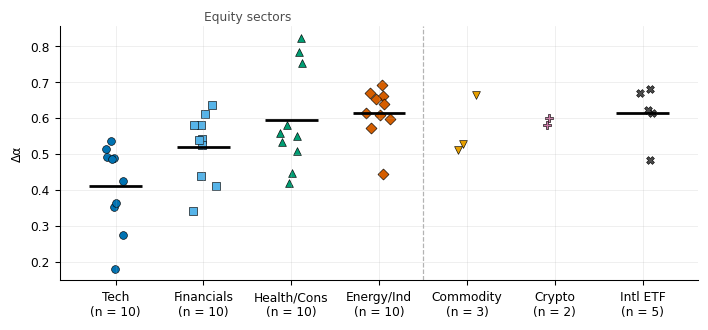


Half-sample stability of Δα: Spearman ρ = 0.09 (p = 0.54); mean |Δ| = 0.168
[robustness grid] 7.4 s

Robustness of Δα across MF-DFA specifications:
               spearman_vs_baseline  mean_delta_alpha  mean_abs_change
baseline                      1.000             0.548            0.000
q in [-10,10]                 0.990             0.558            0.028
q in [-20,20]                 0.994             0.605            0.057
scale_max=400                 0.874             0.582            0.048
scale_min=10                  0.882             0.589            0.052
poly order 2                  0.864             0.541            0.042
overlap 0.5                   0.968             0.543            0.024


,spearman_vs_baseline,mean_delta_alpha,mean_abs_change
baseline,1.000000,0.548076,0.000000
"q in [-10,10]",0.989628,0.558123,0.028237
"q in [-20,20]",0.994430,0.605208,0.057131
scale_max=400,0.874094,0.581661,0.048294
scale_min=10,0.882353,0.589467,0.052440
poly order 2,0.863529,0.541033,0.041660
overlap 0.5,0.968403,0.542618,0.023822


In [7]:
# ═════════════════════════════ §4  CROSS-SECTION, STABILITY, ROBUSTNESS ═════════════════════════════
# --- 4a. Δα by asset class + OLS with heteroskedasticity-robust (HC3) SEs ---
R_all = pd.concat(returns_A, axis=1, sort=False)
corr_mat = R_all.corr(min_periods=250)                       # pairwise-complete (crypto trades weekends)
avg_corr = (corr_mat.sum() - 1) / (corr_mat.notna().sum() - 1)      # mean correlation with the other assets
reg = res[["delta_alpha", "H2", "group"]].copy()
reg["log_vol"]  = np.log(summary["ann_vol"].astype(float))
reg["avg_corr"] = avg_corr
fit = smf.ols("delta_alpha ~ C(group, Treatment('Tech')) + log_vol + avg_corr", data=reg).fit(cov_type="HC3")
print(fit.summary().tables[1]); print(f"N={int(fit.nobs)}  R²={fit.rsquared:.3f}  (HC3 robust SEs; small N → treat as descriptive)")
savetable(pd.DataFrame({"coef": fit.params, "se": fit.bse, "p": fit.pvalues}), "ols_delta_alpha.csv")

fig, ax = plt.subplots(figsize=(FIG_W_2COL, 3.0)); rng_j = rng_for("jitter")
for i, g in enumerate(GROUP_ORDER):
    d = reg[reg["group"] == g]
    ax.scatter(i + rng_j.uniform(-.15, .15, len(d)), d["delta_alpha"], c=CLASS_COLORS[g], marker=GROUP_MARKERS[g], edgecolor="k", lw=.4, s=26)
    if len(d) >= 5: ax.hlines(d["delta_alpha"].mean(), i - .3, i + .3, color="k", lw=1.8)      # no mean bar for n < 5 (points only)
ax.axvline(3.5, color="0.7", lw=.8, ls="--")
ax.text(1.5, 1.01, "Equity sectors", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color="0.3")
ax.set_xticks(range(len(GROUP_ORDER)))
ax.set_xticklabels([f"{g}\n(n = {(reg['group'] == g).sum()})" for g in GROUP_ORDER]); ax.set_ylabel("Δα")
savefig(fig, "figA4_delta_alpha_by_class.png")


# --- 4b. Half-sample stability (no resampling bias, unlike a block bootstrap) ---
h1, h2 = {}, {}
for t in TICKERS_A:
    x = returns_A[t].values; m = len(x) // 2
    h1[t], h2[t] = da_of(x[:m])[0], da_of(x[m:])[0]
stab = pd.DataFrame({"first_half": h1, "second_half": h2}); stab["group"] = [GROUP[t] for t in stab.index]
rho, p_rho = stats.spearmanr(stab["first_half"], stab["second_half"], nan_policy="omit")
print(f"\nHalf-sample stability of Δα: Spearman ρ = {rho:.2f} (p = {p_rho:.3g}); mean |Δ| = {np.nanmean(np.abs(stab.first_half-stab.second_half)):.3f}")
savetable(stab, "delta_alpha_half_sample.csv")
# Fig. A.2 (half-sample scatter) is drawn in the REVISION section, after the noise benchmark (item 9) is available.

# --- 4c. Robustness grid: does the cross-sectional ranking survive different MF-DFA settings? ---
SPECS = {
    "baseline":        {},
    "q in [-10,10]":   dict(q=list(np.arange(-10, 10.1, 2.5))),
    "q in [-20,20]":   dict(q=list(np.arange(-20, 20.1, 5.0))),
    "scale_max=400":   dict(smax=400),
    "scale_min=10":    dict(smin=10),
    "poly order 2":    dict(po=2),
    "overlap 0.5":     dict(ov=0.5),
}
with timed("robustness grid"):
    grid = pd.DataFrame({name: {t: da_of(returns_A[t].values, **kw)[0] for t in TICKERS_A} for name, kw in SPECS.items()})
rob = pd.DataFrame({name: dict(spearman_vs_baseline=stats.spearmanr(grid["baseline"], grid[name], nan_policy="omit")[0],
                               mean_delta_alpha=grid[name].mean(),
                               mean_abs_change=(grid[name] - grid["baseline"]).abs().mean()) for name in SPECS}).T
print("\nRobustness of Δα across MF-DFA specifications:"); print(rob.round(3).to_string())
savetable(grid, "delta_alpha_robustness_grid.csv"); savetable(rob, "delta_alpha_robustness_summary.csv")

In [8]:
# ═════════════════════════════ §5  ROLLING Δα vs ROLLING PAIRWISE CORRELATION ═════════════════════════════
with timed("load episode data"):
    px_B  = get_panel(COHORT + ["^GSPC"], CFG["START_B"], CFG["END_B"]).dropna()
rB    = np.log(px_B).diff().dropna()
R15   = rB[COHORT]; sp   = rB["^GSPC"]
W, WC = CFG["CORR_WINDOW"], CFG["CORR_WINDOW"]

def mean_pairwise_corr(X):
    c = np.corrcoef(np.asarray(X).T); return c[np.triu_indices(c.shape[0], 1)].mean()

corr60 = pd.Series([mean_pairwise_corr(R15.values[i - WC:i]) for i in range(WC, len(R15) + 1)],
                   index=R15.index[WC - 1:], name="avg_pairwise_corr")
vol60  = (sp.rolling(WC).std() * np.sqrt(252)).rename("vol60")

with timed("rolling MF-DFA"):
    q_r = CFG["ROLL_Q"]; rows = []
    for end in range(CFG["ROLL_WINDOW"], len(sp) + 1, CFG["ROLL_STEP"]):
        d, hq = da_of(sp.values[end - CFG["ROLL_WINDOW"]:end], q=q_r, smin=CFG["ROLL_SCALE_MIN"], smax=CFG["ROLL_SCALE_MAX"], ns=CFG["ROLL_N_SCALES"])
        rows.append((sp.index[end - 1], d, hq[q_r.index(2.0)]))
roll = pd.DataFrame(rows, columns=["date", "delta_alpha", "H2"]).set_index("date")
roll["corr60"] = corr60.reindex(roll.index); roll["vol60"] = vol60.reindex(roll.index)
roll = roll.dropna(); savetable(roll, "rolling_delta_alpha_corr.csv")

# --- association tests: rank correlation, vol-controlled partial, circular-shift null (respects autocorrelation) ---
def _rk(a): return stats.rankdata(a)
def _resid(y, x): X = np.column_stack([np.ones_like(x), x]); return y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
def circ_shift_test(a, b, n_perm, rng):
    ra, rb = _rk(a), _rk(b); obs = np.corrcoef(ra, rb)[0, 1]
    lo = len(a) // 10; ks = rng.integers(lo, len(a) - lo, n_perm)
    null = np.array([np.corrcoef(ra, np.roll(rb, k))[0, 1] for k in ks])
    return obs, (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)

ra, rc, rv = _rk(roll.delta_alpha.values), _rk(roll.corr60.values), _rk(roll.vol60.values)
raw_rho, raw_p = circ_shift_test(roll.delta_alpha.values, roll.corr60.values, CFG["N_PERM"], rng_for("circ_raw"))
pa, pc = _resid(ra, rv), _resid(rc, rv)
par_rho = np.corrcoef(pa, pc)[0, 1]
lo = len(pa) // 10; ks = rng_for("circ_partial").integers(lo, len(pa) - lo, CFG["N_PERM"])
par_p = (np.sum(np.abs([np.corrcoef(pa, np.roll(pc, k))[0, 1] for k in ks]) >= abs(par_rho)) + 1) / (CFG["N_PERM"] + 1)
vol_rho = np.corrcoef(rv, rc)[0, 1]
print(f"\nRolling Δα ({CFG['ROLL_WINDOW']}d window) vs {WC}d mean pairwise corr — {len(roll)} overlapping windows")
print(f"  Spearman ρ (raw)                = {raw_rho:+.3f}  circular-shift p = {raw_p:.3f}")
print(f"  Spearman ρ (controlling for vol) = {par_rho:+.3f}  circular-shift p = {par_p:.3f}")
print(f"  (corr vs vol: ρ = {vol_rho:+.2f} — why the control matters, cf. Forbes & Rigobon 2002)")
print("  NB: windows overlap heavily → ordinary p-values would be invalid; the circular-shift null keeps autocorrelation.")

EPISODES = [(b["start"], b["end"], b["label"]) for b in EPISODE_BANDS]
# Fig. 6 is drawn right after Table 2 (section 9c), so title/caption numbers come from the table itself.

[load episode data] 0.4 s
[rolling MF-DFA] 1.1 s

Rolling Δα (1000d window) vs 60d mean pairwise corr — 243 overlapping windows
  Spearman ρ (raw)                = -0.118  circular-shift p = 0.881
  Spearman ρ (controlling for vol) = +0.119  circular-shift p = 0.884
  (corr vs vol: ρ = +0.71 — why the control matters, cf. Forbes & Rigobon 2002)
  NB: windows overlap heavily → ordinary p-values would be invalid; the circular-shift null keeps autocorrelation.


60-day mean pairwise correlation, 15 DJIA stocks, circular block bootstrap (block=5, B=1000):
                           window_end  mean_corr  ci_lo  ci_hi   Δ vs previous (95% CI)
snapshot                                                                               
Pre-bubble (Jan 2006)      2006-01-31      0.230  0.146  0.318                      NaN
Pre-crash peak (Oct 2007)  2007-10-09      0.535  0.437  0.621  +0.308 [+0.175, +0.438]
During crash (Oct 2008)    2008-10-10      0.576  0.452  0.675  +0.037 [-0.112, +0.179]

Build-up slope (2006-01 → 2007-10): +0.1146/yr  95% HAC CI [+0.0304, +0.1988]   (slide reported +0.0735/yr, no CI)
Placebo: slope exceeds 87% of all 445-day windows (n=535) → NOT unusual build-up

Reconciliation: max of 60d rolling mean corr in Sep-2008…Jun-2009 = 0.729 on 2008-12-01 (slide text says 0.72, heat-map says 0.461 — make the paper use ONE definition)


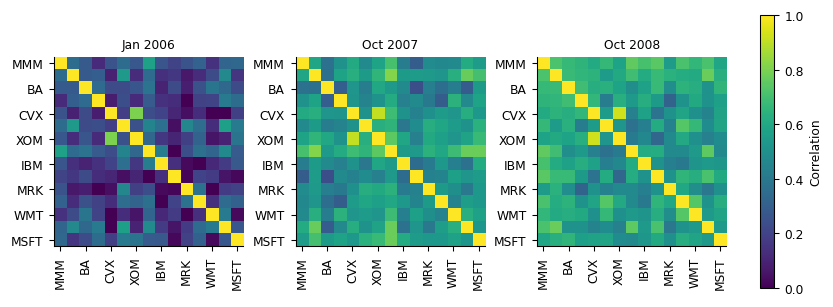

In [9]:
# ═════════════════════════════ §6  CORRELATION BUILD-UP — with proper statistics ═════════════════════════════
def snap_window(date, w=WC):
    i = R15.index.searchsorted(pd.Timestamp(date), side="right"); return R15.iloc[i - w:i]

def boot_mean_corr(win, B, block, rng):
    X = win.values; n = len(X); nb = int(np.ceil(n / block)); out = np.empty(B)
    for b in range(B):
        idx = ((rng.integers(0, n, nb)[:, None] + np.arange(block)) % n).ravel()[:n]
        out[b] = mean_pairwise_corr(X[idx])
    return out

SNAPS = {"Pre-bubble (Jan 2006)": "2006-01-31", "Pre-crash peak (Oct 2007)": "2007-10-09", "During crash (Oct 2008)": "2008-10-10"}
boots, rows = {}, []
for lab, d in SNAPS.items():
    win = snap_window(d); bs = boot_mean_corr(win, CFG["N_BOOT"], CFG["BOOT_BLOCK"], rng_for("boot_" + lab)); boots[lab] = bs
    rows.append(dict(snapshot=lab, window_end=str(win.index[-1].date()), mean_corr=mean_pairwise_corr(win),
                     ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5)))
snap = pd.DataFrame(rows).set_index("snapshot")
labs = list(SNAPS)
for a, b in ((labs[0], labs[1]), (labs[1], labs[2])):
    d = boots[b] - boots[a]; snap.loc[b, f"Δ vs previous (95% CI)"] = f"{d.mean():+.3f} [{np.percentile(d,2.5):+.3f}, {np.percentile(d,97.5):+.3f}]"
print(f"{WC}-day mean pairwise correlation, {len(COHORT)} DJIA stocks, circular block bootstrap (block={CFG['BOOT_BLOCK']}, B={CFG['N_BOOT']}):")
print(snap.round(3).to_string()); savetable(snap, "correlation_snapshots.csv")

# build-up trend with HAC (Newey–West) SEs — rolling series is heavily autocorrelated
seg = corr60["2006-01-01":"2007-10-09"]; tyr = (seg.index - seg.index[0]).days.values / 365.25
ols = sm.OLS(seg.values, sm.add_constant(tyr)).fit(cov_type="HAC", cov_kwds=dict(maxlags=WC))
slope, (lo_s, hi_s) = ols.params[1], ols.conf_int()[1]
print(f"\nBuild-up slope (2006-01 → 2007-10): {slope:+.4f}/yr  95% HAC CI [{lo_s:+.4f}, {hi_s:+.4f}]   (slide reported +0.0735/yr, no CI)")

# placebo: where does that slope rank among ALL equally long windows in 2003-2026?
L = len(seg); sl_all = np.array([np.polyfit(np.arange(L) / 252, corr60.values[i:i + L], 1)[0] for i in range(0, len(corr60) - L, 10)])
pct = 100 * (sl_all < slope).mean()
print(f"Placebo: slope exceeds {pct:.0f}% of all {L}-day windows (n={len(sl_all)}) → {'unusual' if pct > 90 else 'NOT unusual'} build-up")

# reconcile with the slide: which number is the 'crash peak' of the rolling series?
cr = corr60["2008-09-01":"2009-06-30"]
print(f"\nReconciliation: max of {WC}d rolling mean corr in Sep-2008…Jun-2009 = {cr.max():.3f} on {cr.idxmax().date()} "
      f"(slide text says 0.72, heat-map says 0.461 — make the paper use ONE definition)")
fig, axs = plt.subplots(1, 3, figsize=(FIG_W_2COL, 3.0), constrained_layout=True)
tick_ix = list(range(0, len(COHORT), 2))                      # every other ticker keeps 8 pt labels readable
for ax, (lab, d) in zip(axs, SNAPS.items()):
    win = snap_window(d); Cm = np.corrcoef(win.values.T)
    im = ax.imshow(Cm, vmin=0, vmax=1, cmap="viridis"); ax.grid(False)
    ax.set_xticks(tick_ix); ax.set_yticks(tick_ix)
    ax.set_xticklabels([COHORT[i] for i in tick_ix], rotation=90); ax.set_yticklabels([COHORT[i] for i in tick_ix])
    ax.set_title(pd.Timestamp(snap.loc[lab, "window_end"]).strftime("%b %Y"))     # short panel title; snapshot means are in Table 1
fig.colorbar(im, ax=axs, shrink=.85, label="Correlation"); savefig(fig, "figA1_corr_heatmaps.png")


In [10]:
# ═════════════════════════════ §7  √t SCALING → VARIANCE-RATIO TEST ═════════════════════════════
# The original table's "Ratio" column was σ_k / σ_daily (≈ √k by construction), NOT actual/expected. Fixed here.
def variance_ratio(r, k):
    """Lo–MacKinlay (1988) VR(k) with heteroskedasticity-robust z*."""
    r = np.asarray(r); T = len(r); mu = r.mean()
    s1 = np.sum((r - mu) ** 2) / (T - 1)
    rk = np.convolve(r, np.ones(k), "valid")
    m = k * (T - k + 1) * (1 - k / T)
    sk = np.sum((rk - k * mu) ** 2) / m
    vr = sk / s1; d = (r - mu) ** 2; den = d.sum() ** 2
    theta = sum((2 * (k - j) / k) ** 2 * (np.sum(d[j:] * d[:-j]) / den) * T for j in range(1, k))
    z = (vr - 1) * np.sqrt(T) / np.sqrt(theta)
    return vr, z, 2 * (1 - stats.norm.cdf(abs(z))), rk.std(ddof=1), r.std(ddof=1) * np.sqrt(k)

with timed("scaling law"):
    rows, periods = [], {}
    for name, tk in (("DJIA", "^DJI"), ("Nasdaq", "^IXIC")):
        ser = np.log(get_close(tk, CFG["START_C"], CFG["END_C"])).diff().dropna(); periods[name] = (str(ser.index[0].date()), str(ser.index[-1].date())); r = ser.values
        for k in (5, 21, 63):
            vr, z, p, sig_act, sig_exp = variance_ratio(r, k)
            rows.append(dict(index=name, horizon_days=k, sigma_expected=sig_exp, sigma_actual=sig_act,
                             actual_over_expected=sig_act / sig_exp, VR=vr, z_star=z, p_value=p))
scal = pd.DataFrame(rows)
from statsmodels.stats.multitest import multipletests
scal["p_BH"]   = multipletests(scal["p_value"].values, method="fdr_bh")[1]      # Benjamini-Hochberg across the six tests
scal["p_Holm"] = multipletests(scal["p_value"].values, method="holm")[1]
print(scal.round(4).to_string(index=False)); savetable(scal, "scaling_variance_ratio.csv", index=False)
vr_caption = (f"Sample: DJIA {periods['DJIA'][0]} to {periods['DJIA'][1]}; Nasdaq {periods['Nasdaq'][0]} to {periods['Nasdaq'][1]} (daily log returns; download end date "
              f"{CFG['END_C']} is exclusive). Lo-MacKinlay VR(k) with heteroskedasticity-robust z*. p_BH and p_Holm adjust across all six tests.")
(TABLES / "scaling_variance_ratio_caption.txt").write_text(vr_caption); print(vr_caption)

print("VR<1 → mean reversion (sub-√t growth); VR>1 → momentum. z* is robust to heteroskedasticity.")

[scaling law] 0.1 s
 index  horizon_days  sigma_expected  sigma_actual  actual_over_expected     VR  z_star  p_value   p_BH  p_Holm
  DJIA             5          0.0248        0.0231                0.9329 0.8708 -2.1275   0.0334 0.1910  0.2003
  DJIA            21          0.0508        0.0454                0.8921 0.7979 -1.5246   0.1274 0.1910  0.4804
  DJIA            63          0.0880        0.0714                0.8105 0.6621 -1.6767   0.0936 0.1910  0.4680
Nasdaq             5          0.0327        0.0315                0.9642 0.9302 -1.5543   0.1201 0.1910  0.4804
Nasdaq            21          0.0671        0.0646                0.9641 0.9318 -0.6839   0.4940 0.5928  0.9881
Nasdaq            63          0.1161        0.1144                0.9854 0.9780 -0.1345   0.8930 0.8930  0.9881
Sample: DJIA 1992-01-03 to 2023-12-29; Nasdaq 1990-01-03 to 2023-12-29 (daily log returns; download end date 2024-01-01 is exclusive). Lo-MacKinlay VR(k) with heteroskedasticity-robust z*. p_BH an

In [11]:
# ═════════════════════════════ §8  PAPER NUMBERS + REPRODUCIBILITY ARTIFACTS ═════════════════════════════
def _v(pkg):
    try: return metadata.version(pkg)
    except Exception: return "n/a"
PKGS = ["numpy", "scipy", "pandas", "matplotlib", "statsmodels", "joblib", "yfinance", "ipykernel"]
(BASE / "requirements.txt").write_text("\n".join(f"{p}=={_v(p)}" for p in PKGS if _v(p) != "n/a") + "\n")

# Guard: §9e / §10b later reuse the name `raw_p` for joblib result lists. Run this cell in order (before them).
assert np.isscalar(raw_p), "raw_p was overwritten by a later cell (§9e/§10b); re-run §5 first, then this cell."

paper = dict(
    n_assets=int(len(res)), n_surrogates=CFG["N_SURR"],
    mean_delta_alpha=float(res.delta_alpha.mean()),
    n_sig_shuffle_bh=int((res.q_shuffle < .05).sum()), n_sig_iaaft_bh=int((res.q_iaaft < .05).sum()), n_sig_phase_bh=int((res.q_phase < .05).sum()),
    # NB: "fat_tail" here = shuffle_mean / width, i.e. it INCLUDES the Gaussian/finite-size floor (see the four-way decomposition for the split)
    mean_share_fat_tail_pct=float(res.share_fat_tail_pct.mean()), mean_share_linear_pct=float(res.share_linear_pct.mean()),
    mean_share_nonlinear_pct=float(res.share_nonlinear_pct.mean()), mean_share_temporal_pct=float(res.share_temporal_pct.mean()),
    half_sample_spearman=float(rho),
    rolling_rho_raw=float(raw_rho), rolling_p_raw=float(raw_p), rolling_rho_vol_controlled=float(par_rho), rolling_p_vol_controlled=float(par_p),
    buildup_slope_per_yr=float(slope), buildup_slope_ci=[float(lo_s), float(hi_s)], buildup_slope_placebo_percentile=float(pct),
    corr_snapshots=snap[["mean_corr", "ci_lo", "ci_hi"]].round(4).to_dict("index"),
)
(BASE / "paper_numbers.json").write_text(json.dumps(paper, indent=1))

# Preliminary metadata (later cells read `meta`). The data manifest keeps growing when §10a downloads the 2008-start files,
# so run the refresh cell once before the "change log, suggested text" cell to get the final digest.
data_hashes = {k: v["sha256"] for k, v in _manifest().items()}
meta = dict(run_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"), config=CFG, config_hash=CFG_HASH,
            data_mode=CFG["DATA_MODE"], python=platform.python_version(), platform=platform.platform(),
            packages={p: _v(p) for p in PKGS}, timings_s=TIMINGS,
            data_manifest_sha256=hashlib.sha256(json.dumps(data_hashes, sort_keys=True).encode()).hexdigest(),
            n_cached_files=len(data_hashes))
meta["code_sha256"] = {f: _sha256(Path(f)) for f in ("flr_core.py", "figstyle.py") if Path(f).exists()}
(BASE / "config_hash.txt").write_text(CFG_HASH + "\n")
Path("requirements.lock.txt").write_text((BASE / "requirements.txt").read_text())      # exact versions of THIS run
(BASE / "run_metadata.json").write_text(json.dumps(meta, indent=1, default=str))
print(json.dumps(paper, indent=1))
print("\nrun metadata →", BASE / "run_metadata.json", "| data-manifest digest (preliminary)", meta["data_manifest_sha256"][:16])

print("\nFiles written:")
for p in sorted(BASE.rglob("*")):
    if p.is_file() and p.parent.name not in ("data_cache", "data_synthetic"):
        print("  ", p.relative_to(BASE))

{
 "n_assets": 50,
 "n_surrogates": 500,
 "mean_delta_alpha": 0.5480762642548763,
 "n_sig_shuffle_bh": 36,
 "n_sig_iaaft_bh": 34,
 "n_sig_phase_bh": 49,
 "mean_share_fat_tail_pct": 73.01701946872404,
 "mean_share_linear_pct": 0.6676362628605594,
 "mean_share_nonlinear_pct": 26.315344268415398,
 "mean_share_temporal_pct": 26.982980531275956,
 "half_sample_spearman": 0.08869147659063625,
 "rolling_rho_raw": -0.11816375378223366,
 "rolling_p_raw": 0.8810594702648675,
 "rolling_rho_vol_controlled": 0.11861804427008364,
 "rolling_p_vol_controlled": 0.8840579710144928,
 "buildup_slope_per_yr": 0.11457386583079848,
 "buildup_slope_ci": [
  0.03036294479390257,
  0.1987847868676944
 ],
 "buildup_slope_placebo_percentile": 87.10280373831776,
 "corr_snapshots": {
  "Pre-bubble (Jan 2006)": {
   "mean_corr": 0.2299,
   "ci_lo": 0.1461,
   "ci_hi": 0.3179
  },
  "Pre-crash peak (Oct 2007)": {
   "mean_corr": 0.535,
   "ci_lo": 0.4374,
   "ci_hi": 0.6211
  },
  "During crash (Oct 2008)": {
   "mean

### Reproducing this run exactly
1. `pip install -r flr_run/requirements.txt` (versions of the machine that produced the results).
2. Keep `flr_run/data_cache/` (CSVs + `manifest.json`) with the notebook — or ship it as the paper's data appendix. The notebook verifies every file's SHA-256 before use.
3. Run All. All randomness comes from `CFG["SEED"]` via per-task `SeedSequence([seed, crc32(name)])`, so results do **not** depend on `n_jobs`, CPU count or task order.
4. Compare `run_metadata.json` (`config_hash`, `data_manifest_sha256`) between machines; if both match and package versions match, `paper_numbers.json` should be identical.

Caveats to state in the paper: yfinance auto-adjusted prices change when dividends/splits are revised (hence the frozen cache); the asset universe is current-constituent (survivorship); Δα from the Legendre transform depends on the q-range and smoothing (see §4c).

Four-way decomposition of Δα (aggregate over 50 assets; 95% bootstrap CI over assets):
                            aggregate_%  ci_lo  ci_hi  median_asset_%
Gaussian/finite-size floor         42.1   40.4   44.2            40.6
Extra fat tails                    26.0   22.4   30.1            23.5
Linear correlation                  2.0    0.2    3.7             2.5
Nonlinear dependence               29.9   25.4   33.6            32.6

By asset class (aggregate %):
             Gaussian/finite-size floor  Extra fat tails  Linear correlation  Nonlinear dependence
group                                                                                             
Commodity                          41.3             41.6                 2.3                  14.9
Crypto                             32.8             36.7                -7.0                  37.5
Energy/Ind                         41.0             20.3                 5.2                  33.5
Financials                         42

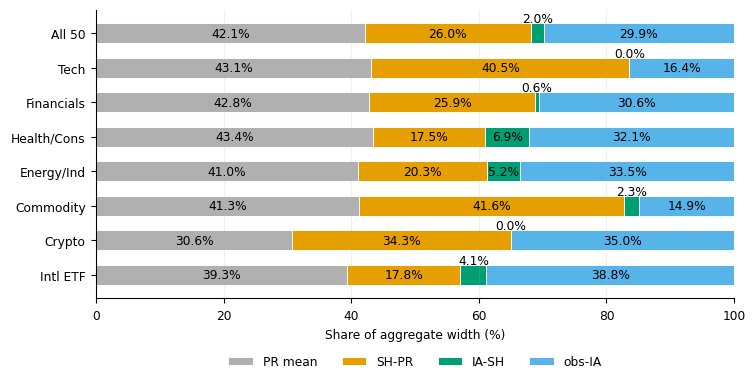

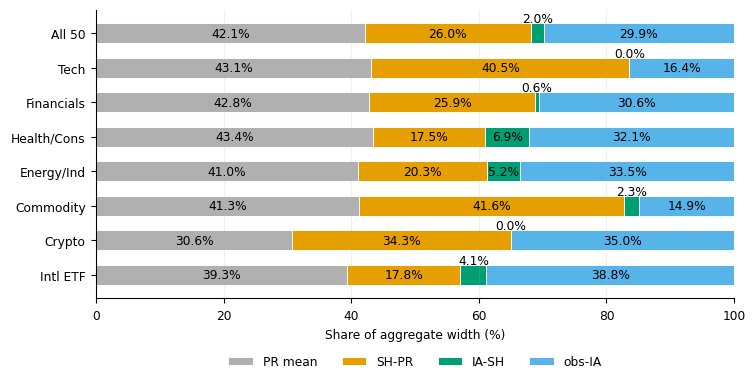

In [12]:
# ═════════ §9a  FOUR-WAY DECOMPOSITION OF Δα (adds the Gaussian / finite-size floor) ═════════
COMP = {
    "Gaussian/finite-size floor": lambda d: d["phase_mean"],
    "Extra fat tails":            lambda d: d["shuffle_mean"] - d["phase_mean"],
    "Linear correlation":         lambda d: d["iaaft_mean"] - d["shuffle_mean"],
    "Nonlinear dependence":       lambda d: d["delta_alpha"] - d["iaaft_mean"],
}
comp = pd.DataFrame({k: f(res) for k, f in COMP.items()}); comp["group"] = res["group"]

def agg_share(df):                      # aggregate share in %, one value per component
    return 100 * df[list(COMP)].sum() / df[list(COMP)].sum().sum()

rb = rng_for("decomp_boot"); B = 2000
boot = np.array([agg_share(comp.iloc[rb.integers(0, len(comp), len(comp))]).values for _ in range(B)])
dec = pd.DataFrame({"aggregate_%": agg_share(comp),
                    "ci_lo": np.percentile(boot, 2.5, axis=0), "ci_hi": np.percentile(boot, 97.5, axis=0),
                    "median_asset_%": (100 * comp[list(COMP)].div(res["delta_alpha"], axis=0)).median()})
print("Four-way decomposition of Δα (aggregate over 50 assets; 95% bootstrap CI over assets):")
print(dec.round(1).to_string()); savetable(dec, "decomposition_four_way.csv")

by_g = comp.groupby("group").apply(agg_share); print("\nBy asset class (aggregate %):"); print(by_g.round(1).to_string())
savetable(by_g, "decomposition_by_class.csv")

# ── Stacked share bars: shared by the by-class figure and Fig. 4. Labels follow Eq. (3): PR mean, SH-PR, IA-SH, obs-IA. ──
COMP_LABELS = {"Gaussian/finite-size floor": "PR mean", "Extra fat tails": "SH-PR", "Linear correlation": "IA-SH", "Nonlinear dependence": "obs-IA"}
COMP_COLORS = ["#B0B0B0", "#E69F00", "#009E73", "#56B4E9"]

def plot_shares(tbl, ci=None, h=2.8, name="fig_shares"):
    """tbl: rows x COMP columns in % (rows sum to 100). ci: {row: {comp: (lo, hi)}} -> bootstrap 95% CI of each segment's share,
    printed as text under the percentage (no whiskers)."""
    fig, ax = plt.subplots(figsize=(FIG_W_2COL, h)); yp = np.arange(len(tbl)); left = np.zeros(len(tbl))
    for c, col in zip(COMP, COMP_COLORS):
        w = tbl[c].values
        ax.barh(yp, w, left=left, color=col, height=.58, label=COMP_LABELS[c], edgecolor="white", lw=.6)
        for yi, (l0, wi, row) in enumerate(zip(left, w, tbl.index)):
            small = wi < 5
            txt = f"{wi:.1f}%"
            if ci is not None and row in ci and not small:
                lo, hi = ci[row][c]; txt += f"\n[{lo:.1f}–{hi:.1f}]"
            ax.text(l0 + wi / 2, yi - (.42 if small else 0.0), txt, ha="center", va="center", fontsize=8)
        left = left + w
    ax.set_yticks(yp); ax.set_yticklabels(tbl.index); ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Share of aggregate width (%)")
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.22 if h < 3 else -.16), ncol=4, frameon=False)
    savefig(fig, name); return fig
    savefig(fig, name); return fig

tbl_raw = pd.concat([dec["aggregate_%"].rename("All 50").to_frame().T, by_g.loc[GROUP_ORDER]])
print("[shares] negative components set to 0 and rows renormalized in this plot:", int((tbl_raw < 0).sum().sum()), "cells (reported tables are unclipped)")
tbl = tbl_raw.clip(lower=0); tbl = 100 * tbl.div(tbl.sum(axis=1), axis=0)
plot_shares(tbl, h=3.4, name="figA_decomposition_by_class.png")


[ex-COVID Δα] 1.2 s
Dropping 2020-02-19 → 2020-06-30 (days removed, series concatenated):
  mean Δα 0.548 → 0.445  (mean change -0.103; 40/50 assets fall)
  rank correlation full vs ex-COVID: Spearman ρ = 0.39
  by class (mean Δα):
              full  ex_covid
group                       
Commodity    0.569     0.481
Crypto       0.590     0.549
Energy/Ind   0.616     0.469
Financials   0.521     0.402
Health/Cons  0.596     0.500
Intl ETF     0.615     0.454
Tech         0.412     0.373

Defensive names (Δα full → ex-COVID):
       full  ex_covid  change
KO    0.824     0.604  -0.220
PEP   0.784     0.510  -0.274
JNJ   0.753     0.596  -0.157
PG    0.558     0.381  -0.177
WMT   0.534     0.558   0.024
COST  0.509     0.518   0.010
MRK   0.419     0.370  -0.049
ABBV  0.551     0.489  -0.062
PFE   0.581     0.503  -0.078
UNH   0.448     0.467   0.019

Top-8 by Δα, full:  ['KO', 'PEP', 'JNJ', 'BA', 'EWU', 'LMT', 'EWG', 'CL=F']
Top-8 by Δα, ex-COVID: ['KO', 'JNJ', 'UPS', 'RTX', 'WMT', 'IN

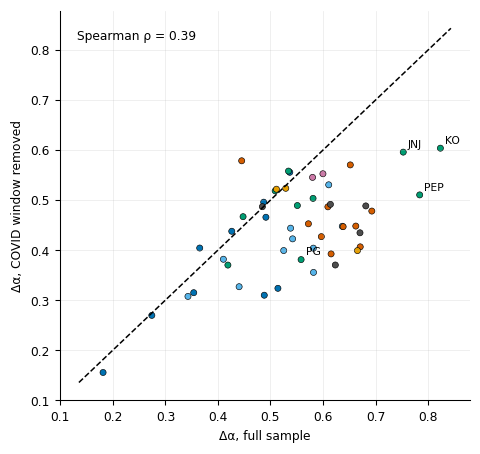

In [13]:
# ═════════ §9b  EX-COVID CHECK: is the high Δα of low-vol defensive names a 2020 effect? ═════════
EXCL = ("2020-02-19", "2020-06-30")      # S&P peak → end of the volatility spike (edit if you prefer another window)
def drop_window(r, a, b): return r[(r.index < pd.Timestamp(a)) | (r.index > pd.Timestamp(b))]

with timed("ex-COVID Δα"):
    exc = pd.Series({t: da_of(drop_window(returns_A[t], *EXCL).values)[0] for t in TICKERS_A})
cmp_ = pd.DataFrame({"full": res["delta_alpha"], "ex_covid": exc, "group": res["group"]}); cmp_["change"] = cmp_.ex_covid - cmp_.full
rho_ec = stats.spearmanr(cmp_.full, cmp_.ex_covid, nan_policy="omit")[0]
print(f"Dropping {EXCL[0]} → {EXCL[1]} (days removed, series concatenated):")
print(f"  mean Δα {cmp_.full.mean():.3f} → {cmp_.ex_covid.mean():.3f}  (mean change {cmp_.change.mean():+.3f}; {int((cmp_.change<0).sum())}/50 assets fall)")
print(f"  rank correlation full vs ex-COVID: Spearman ρ = {rho_ec:.2f}")
print("  by class (mean Δα):"); print(cmp_.groupby("group")[["full", "ex_covid"]].mean().round(3).to_string())
defensive = ["KO", "PEP", "JNJ", "PG", "WMT", "COST", "MRK", "ABBV", "PFE", "UNH"]
print("\nDefensive names (Δα full → ex-COVID):"); print(cmp_.loc[defensive, ["full", "ex_covid", "change"]].round(3).to_string())
print("\nTop-8 by Δα, full: ", cmp_.full.nlargest(8).index.tolist()); print("Top-8 by Δα, ex-COVID:", cmp_.ex_covid.nlargest(8).index.tolist())
savetable(cmp_, "delta_alpha_ex_covid.csv")

fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.scatter(cmp_.full, cmp_.ex_covid, c=[CLASS_COLORS[g] for g in cmp_.group], edgecolor="k", lw=.4)
for t in defensive[:4]: ax.annotate(t, (cmp_.full[t], cmp_.ex_covid[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")
lim = [min(cmp_.full.min(), cmp_.ex_covid.min()) - .02, max(cmp_.full.max(), cmp_.ex_covid.max()) + .02]
ax.plot(lim, lim, "k--", lw=1); ax.set_xlabel("Δα, full sample"); ax.set_ylabel("Δα, COVID window removed"); ax.text(.04, .95, f"Spearman ρ = {rho_ec:.2f}", transform=ax.transAxes, va="top")
savefig(fig, "fig7_ex_covid.png")

[ex-COVID surrogates] 293.3 s
Decomposition of Δα — full sample vs COVID window (2020-02-19 → 2020-06-30) removed:
                           full sample                ex-COVID            
                           aggregate_% ci_lo ci_hi aggregate_% ci_lo ci_hi
Gaussian/finite-size floor        42.1  40.4  44.2        50.5  48.0  53.0
Extra fat tails                   26.0  22.4  30.1        26.2  21.9  30.7
Linear correlation                 2.0   0.2   3.7         0.4  -1.8   2.5
Nonlinear dependence              29.9  25.4  33.6        23.0  18.7  26.7

mean Δα: 0.548 (full) → 0.445 (ex-COVID)
BH q<0.05, temporal dependence   : full 36/50  →  ex-COVID 14/50
BH q<0.05, nonlinear dependence  : full 34/50  →  ex-COVID 15/50
BH q<0.05, non-Gaussian          : full 49/50  →  ex-COVID 48/50
[Fig. 4] negative components clipped: 0


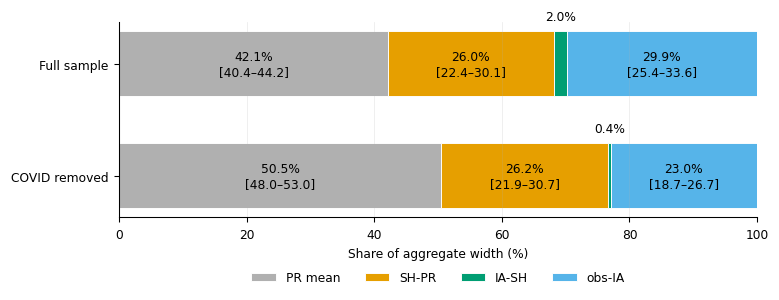

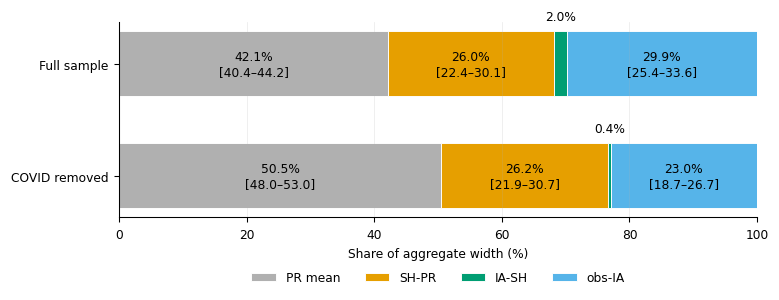

In [14]:
# ═════════ §9d  EX-COVID SURROGATE DECOMPOSITION (does the fat-tail share survive removing 2020?) ═════════
with timed("ex-COVID surrogates"):
    raw_x = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(
        delayed(surrogate_task)(t, drop_window(returns_A[t], *EXCL).values, CFG["N_SURR"], CFG["IAAFT_ITERS"], CFG)
        for t in TICKERS_A)
res_x = pd.DataFrame(raw_x).set_index("ticker").loc[TICKERS_A]; res_x["group"] = [GROUP[t] for t in res_x.index]
for k in ("shuffle", "iaaft", "phase"):
    res_x[f"q_{k}"] = false_discovery_control(res_x[f"p_{k}"].values, method="bh")
savetable(res_x, "delta_alpha_surrogates_ex_covid.csv")

comp_x = pd.DataFrame({k: f(res_x) for k, f in COMP.items()}); comp_x["group"] = res_x["group"]
rb = rng_for("decomp_boot_ex"); boot_x = np.array([agg_share(comp_x.iloc[rb.integers(0, len(comp_x), len(comp_x))]).values for _ in range(B)])
dec_x = pd.DataFrame({"aggregate_%": agg_share(comp_x),
                      "ci_lo": np.percentile(boot_x, 2.5, axis=0), "ci_hi": np.percentile(boot_x, 97.5, axis=0)})
both = pd.concat({"full sample": dec[["aggregate_%", "ci_lo", "ci_hi"]], "ex-COVID": dec_x}, axis=1)
print(f"Decomposition of Δα — full sample vs COVID window ({EXCL[0]} → {EXCL[1]}) removed:"); print(both.round(1).to_string())
savetable(both, "decomposition_full_vs_ex_covid.csv")

n = len(res_x)
print(f"\nmean Δα: {res.delta_alpha.mean():.3f} (full) → {res_x.delta_alpha.mean():.3f} (ex-COVID)")
for k, lab in (("shuffle", "temporal dependence"), ("iaaft", "nonlinear dependence"), ("phase", "non-Gaussian")):
    print(f"BH q<0.05, {lab:22s}: full {(res[f'q_{k}']<.05).sum():>2d}/{n}  →  ex-COVID {(res_x[f'q_{k}']<.05).sum():>2d}/{n}")

t2 = pd.DataFrame({"Full sample": dec["aggregate_%"], "COVID removed": dec_x["aggregate_%"]}).T
print("[Fig. 4] negative components clipped:", int((t2 < 0).sum().sum()))
t2 = t2.clip(lower=0); t2 = 100 * t2.div(t2.sum(axis=1), axis=0)
ci4 = {"Full sample": {c: (dec.loc[c, "ci_lo"], dec.loc[c, "ci_hi"]) for c in COMP},
       "COVID removed": {c: (dec_x.loc[c, "ci_lo"], dec_x.loc[c, "ci_hi"]) for c in COMP}}
plot_shares(t2, ci=ci4, h=2.3, name="fig4_decomposition_ex_covid.png")


[window sensitivity] 3.6 s
Δα vs 60d mean pairwise correlation, by window length:
        n_windows  rho_raw  p_raw  rho_vol_controlled  p_vol_controlled
window                                                                 
750           256    0.094  0.750               0.287             0.554
1000          243   -0.118  0.875               0.119             0.892
1500          218   -0.277  0.150              -0.249             0.765

Δα before each peak vs maximum during the episode:
 window   episode  delta_alpha_before  max_during  change date_of_max
    750       GFC               0.285       0.414   0.129  2008-11-03
    750     COVID               0.526       0.752   0.226  2020-04-15
    750 2022 bear               0.513       0.523   0.010  2022-02-09
   1000       GFC               0.301       0.681   0.379  2008-10-20
   1000     COVID               0.561       0.811   0.250  2020-03-31
   1000 2022 bear               0.525       0.572   0.047  2022-08-17
   1500     COVI

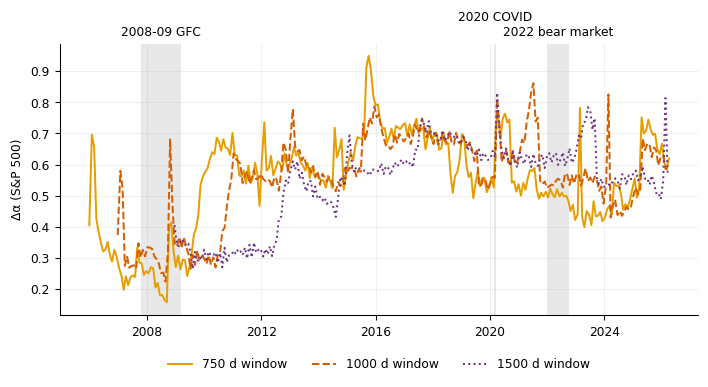

Spearman rho between rolling width (1000 d window) and the 60 d mean pairwise correlation: raw -0.12 (circular-shift p = 0.87); volatility-controlled +0.12 (p = 0.89); 243 overlapping windows. Shaded bands: 2008-09 GFC (2007-10-09 to 2009-03-09); 2020 COVID (2020-02-19 to 2020-03-23); 2022 bear market (2022-01-03 to 2022-10-12).
[check] section-5 run (other permutation stream): raw p = 0.881, vol-controlled p = 0.884; Table 2: 0.875 / 0.892. Differences are Monte-Carlo noise (2000 shifts); cite Table 2.


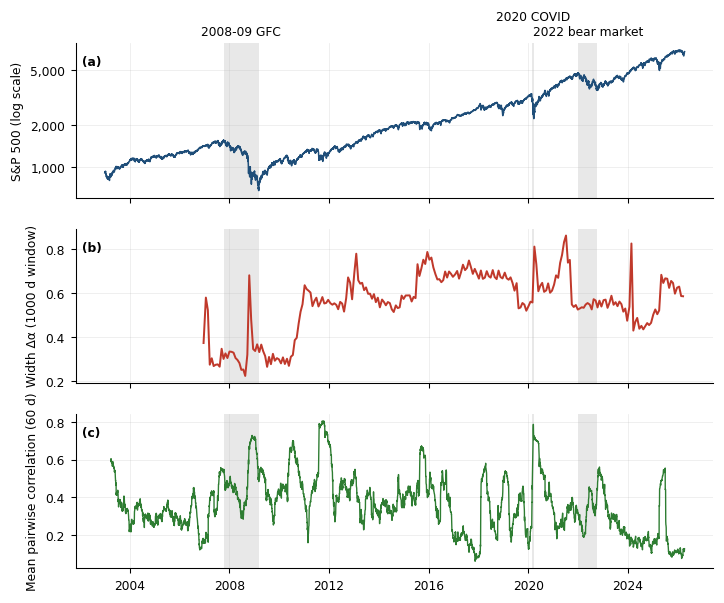

In [15]:
# ═════════ §9c  ROLLING-WINDOW SENSITIVITY (750 / 1000 / 1500 days) + episode table ═════════
WINDOWS = [750, 1000, 1500]
def rolling_da(x, dates, window, step):
    out = {}
    for end in range(window, len(x) + 1, step):
        out[dates[end - 1]] = da_of(x[end - window:end], q=CFG["ROLL_Q"], smin=CFG["ROLL_SCALE_MIN"],
                                    smax=CFG["ROLL_SCALE_MAX"], ns=CFG["ROLL_N_SCALES"])[0]
    return pd.Series(out)

rows, series = [], {}
with timed("window sensitivity"):
    for Wn in WINDOWS:
        s = rolling_da(sp.values, sp.index, Wn, CFG["ROLL_STEP"]); series[Wn] = s
        d = pd.DataFrame({"da": s, "corr": corr60, "vol": vol60}).dropna()
        rho_r, p_r = circ_shift_test(d.da.values, d["corr"].values, CFG["N_PERM"], rng_for(f"w{Wn}_raw"))
        pa_, pc_ = _resid(_rk(d.da.values), _rk(d.vol.values)), _resid(_rk(d["corr"].values), _rk(d.vol.values))
        rho_p = np.corrcoef(pa_, pc_)[0, 1]; lo = len(pa_) // 10
        ks = rng_for(f"w{Wn}_par").integers(lo, len(pa_) - lo, CFG["N_PERM"])
        p_p = (np.sum(np.abs([np.corrcoef(pa_, np.roll(pc_, k))[0, 1] for k in ks]) >= abs(rho_p)) + 1) / (CFG["N_PERM"] + 1)
        rows.append(dict(window=Wn, n_windows=len(d), rho_raw=rho_r, p_raw=p_r, rho_vol_controlled=rho_p, p_vol_controlled=p_p))
sens = pd.DataFrame(rows).set_index("window"); print("Δα vs 60d mean pairwise correlation, by window length:"); print(sens.round(3).to_string())
savetable(sens, "rolling_window_sensitivity.csv")

# episode table: Δα just BEFORE each peak vs the highest Δα within the episode (+60 days)
EPI = [(b["start"], b["end"], b["short"]) for b in EPISODE_BANDS]
ep = []
for Wn, s in series.items():
    for a, b, lab in EPI:
        pre = s[:pd.Timestamp(a)]; inside = s[pd.Timestamp(a):pd.Timestamp(b) + pd.Timedelta(days=60)]
        if len(pre) and len(inside):
            ep.append(dict(window=Wn, episode=lab, delta_alpha_before=pre.iloc[-1], max_during=inside.max(),
                           change=inside.max() - pre.iloc[-1], date_of_max=inside.idxmax().date()))
ep = pd.DataFrame(ep); print("\nΔα before each peak vs maximum during the episode:"); print(ep.round(3).to_string(index=False))
savetable(ep, "rolling_episode_table.csv", index=False)

fig, ax = plt.subplots(figsize=(FIG_W_2COL, 3.2))
for Wn, c, ls in zip(WINDOWS, ["#E69F00", "#D55E00", "#6c3483"], ["-", "--", ":"]): ax.plot(series[Wn], c=c, ls=ls, lw=1.3, label=f"{Wn} d window")
def label_bands(ax):
    for k, b in enumerate(EPISODE_BANDS):
        s, e = pd.Timestamp(b["start"]), pd.Timestamp(b["end"]); ax.axvspan(s, e, color="#999", alpha=.22, lw=0)
        ax.annotate(b["label"], xy=(s + (e - s) / 2, 1.0), xycoords=("data", "axes fraction"), xytext=(0, 3 + 10 * (k % 2)),
                    textcoords="offset points", ha="center", va="bottom", fontsize=8)      # staggered so neighbouring labels never collide
label_bands(ax)
ax.set_ylabel("Δα (S&P 500)"); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=3, frameon=False)
savefig(fig, "figA3_window_sensitivity.png")

# ── Fig. 6 (paper): S&P 500, rolling width, rolling correlation. All numbers come from Table 2 (`sens`), not from section 5. ──
Wf = CFG["ROLL_WINDOW"]; rw = sens.loc[Wf]
fig6_numbers = dict(window=int(Wf), n_windows=int(rw["n_windows"]), rho_raw=float(rw["rho_raw"]), p_raw=float(rw["p_raw"]),
                    rho_vol_controlled=float(rw["rho_vol_controlled"]), p_vol_controlled=float(rw["p_vol_controlled"]))
fig6_caption = (f"Spearman rho between rolling width ({Wf} d window) and the {WC} d mean pairwise correlation: raw {fig6_numbers['rho_raw']:+.2f} "
                f"(circular-shift p = {fig6_numbers['p_raw']:.2f}); volatility-controlled {fig6_numbers['rho_vol_controlled']:+.2f} "
                f"(p = {fig6_numbers['p_vol_controlled']:.2f}); {fig6_numbers['n_windows']} overlapping windows. "
                f"Shaded bands: " + "; ".join(f"{b['label']} ({b['start']} to {b['end']})" for b in EPISODE_BANDS) + ".")
(TABLES / "fig6_caption_numbers.txt").write_text(fig6_caption); print(fig6_caption)
print(f"[check] section-5 run (other permutation stream): raw p = {paper['rolling_p_raw']:.3f}, vol-controlled p = {paper['rolling_p_vol_controlled']:.3f}; "
      f"Table 2: {fig6_numbers['p_raw']:.3f} / {fig6_numbers['p_vol_controlled']:.3f}. Differences are Monte-Carlo noise ({CFG['N_PERM']} shifts); cite Table 2.")
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
fig, axs = plt.subplots(3, 1, figsize=(FIG_W_2COL, 6.2), sharex=True)
axs[0].plot(px_B["^GSPC"], c="#1f4e79", lw=1); axs[0].set_yscale("log"); axs[0].set_ylabel("S&P 500 (log scale)")
axs[0].yaxis.set_major_locator(FixedLocator([1000, 2000, 5000])); axs[0].yaxis.set_major_formatter(FixedFormatter(["1,000", "2,000", "5,000"])); axs[0].yaxis.set_minor_locator(NullLocator())
axs[1].plot(roll.delta_alpha, c="#c0392b", lw=1.3); axs[1].set_ylabel(f"Width Δα ({Wf} d window)")
axs[2].plot(corr60, c="#2e7d32", lw=.9); axs[2].set_ylabel(f"Mean pairwise correlation ({WC} d)")
for a in axs[1:]:
    for b in EPISODE_BANDS: a.axvspan(pd.Timestamp(b["start"]), pd.Timestamp(b["end"]), color="#999", alpha=.22, lw=0)
label_bands(axs[0])
for a, t in zip(axs, "abc"): a.text(.01, .92, f"({t})", transform=a.transAxes, fontweight="bold", va="top")
savefig(fig, "fig6_rolling_episodes.png")


In [16]:
extra = dict(
    decomposition_aggregate_pct=dec["aggregate_%"].round(2).to_dict(),
    decomposition_ci=dec[["ci_lo", "ci_hi"]].round(2).to_dict("index"),
    ex_covid_rank_rho=float(rho_ec), ex_covid_mean_change=float(cmp_.change.mean()),
    window_sensitivity=sens.round(4).to_dict("index"),
)
p = BASE / "paper_numbers.json"; d = json.loads(p.read_text()); d.update(extra)
p.write_text(json.dumps(d, indent=1, default=str)); print("paper_numbers.json updated")

paper_numbers.json updated


[placebo windows] 17.8 s
150 placebo windows of 132 calendar days (none overlapping 2020-02-19 → 2020-06-30)
  mean Δα change, placebo windows: +0.001  (5th–95th pct: -0.007 … +0.009)
  mean Δα change, COVID window  : -0.103   → empirical one-sided p = 0.007
  assets whose Δα falls: COVID 40/50  vs placebo mean 24.2/50

By asset class:
              n  covid_change  placebo_mean  placebo_p05  empirical_p
group                                                                
Commodity     3        -0.087        -0.003       -0.035        0.007
Crypto        2        -0.041         0.002       -0.022        0.026
Energy/Ind   10        -0.147        -0.004       -0.020        0.007
Financials   10        -0.119        -0.004       -0.022        0.007
Health/Cons  10        -0.096         0.010       -0.006        0.007
Intl ETF      5        -0.161        -0.004       -0.024        0.007
Tech         10        -0.039         0.005       -0.008        0.007


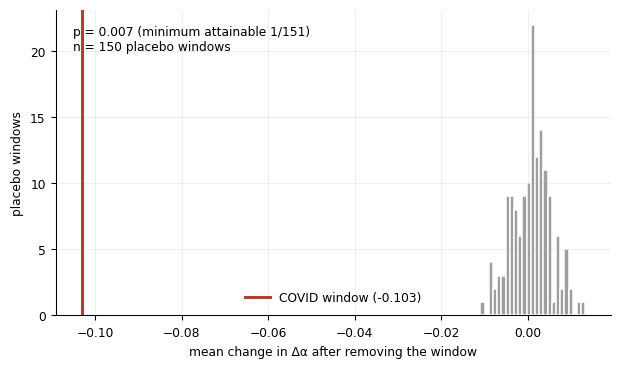

In [17]:
# ═════════ §9e  PLACEBO: how unusual is the COVID window's effect on Δα? ═════════
# Remove K random windows of the SAME calendar length (never overlapping the COVID window), recompute Δα,
# and compare the mean fall in Δα with the fall caused by removing COVID (cmp_.change.mean() from §9b).
K = int(os.environ.get("FLR_N_PLACEBO", 150))
span = pd.Timestamp(EXCL[1]) - pd.Timestamp(EXCL[0])
cand = pd.date_range(pd.Timestamp(CFG["START_A"]) + pd.Timedelta(days=30),
                     pd.Timestamp(CFG["END_A"]) - span - pd.Timedelta(days=30), freq="D")
ok = cand[(cand + span < pd.Timestamp(EXCL[0])) | (cand > pd.Timestamp(EXCL[1]))]
starts = pd.DatetimeIndex(rng_for("placebo_windows").choice(ok, K, replace=False)).sort_values()

def placebo_task(ticker, r, starts, span, cfg):
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS", "SCALE_MIN", "SCALE_MAX", "N_SCALES", "POLY_ORD", "OVERLAP"))
    vals, idx = r.values, r.index; out = np.full(len(starts), np.nan)
    for i, s in enumerate(starts):
        keep = (idx < s) | (idx > s + span)
        _, _, hq = mfdfa_fast(vals[keep], q, smin, smax, ns, po, ov); out[i] = delta_alpha(q, hq)
    return ticker, out

with timed("placebo windows"):
    raw_plc = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(
        delayed(placebo_task)(t, returns_A[t], starts, span, CFG) for t in TICKERS_A)
P = pd.DataFrame({t: v for t, v in raw_plc}, index=starts)[TICKERS_A]           # K × 50 matrix of Δα
chg = P.sub(res["delta_alpha"], axis=1)                                        # change vs full-sample Δα

covid_mean = float(cmp_.change.mean()); plc_mean = chg.mean(axis=1)            # mean change across assets, per placebo
p_emp = (np.sum(plc_mean <= covid_mean) + 1) / (K + 1)
print(f"{K} placebo windows of {span.days} calendar days (none overlapping {EXCL[0]} → {EXCL[1]})")
print(f"  mean Δα change, placebo windows: {plc_mean.mean():+.3f}  (5th–95th pct: {plc_mean.quantile(.05):+.3f} … {plc_mean.quantile(.95):+.3f})")
print(f"  mean Δα change, COVID window  : {covid_mean:+.3f}   → empirical one-sided p = {p_emp:.3f}")
print(f"  assets whose Δα falls: COVID {int((cmp_.change<0).sum())}/50  vs placebo mean {(chg<0).sum(axis=1).mean():.1f}/50")
rows = []
for g in sorted(set(GROUP.values())):
    cols = [t for t in TICKERS_A if GROUP[t] == g]
    rows.append(dict(group=g, n=len(cols), covid_change=cmp_.loc[cols, "change"].mean(),
                     placebo_mean=chg[cols].mean(axis=1).mean(), placebo_p05=chg[cols].mean(axis=1).quantile(.05),
                     empirical_p=(np.sum(chg[cols].mean(axis=1) <= cmp_.loc[cols, "change"].mean()) + 1) / (K + 1)))
by_grp = pd.DataFrame(rows).set_index("group"); print("\nBy asset class:"); print(by_grp.round(3).to_string())
savetable(by_grp, "placebo_by_class.csv"); savetable(chg, "placebo_delta_alpha_change.csv")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(plc_mean, bins=25, color="#9e9e9e", edgecolor="white"); ax.axvline(covid_mean, color="#c0392b", lw=2, label=f"COVID window ({covid_mean:+.3f})")
ax.set_xlabel("mean change in Δα after removing the window"); ax.set_ylabel("placebo windows"); ax.legend(frameon=False)
ax.text(.03, .95, f"p = {p_emp:.3f} (minimum attainable 1/{K+1})\nn = {K} placebo windows", transform=ax.transAxes, va="top"); savefig(fig, "fig10_placebo_windows.png")

In [18]:
# ═════════ §10a  EXTENDED SAMPLE FROM 2008: which assets actually existed? ═════════
START_D, END_D = "2008-01-01", CFG["END_A"]
ELIG_BY = pd.Timestamp("2008-01-31")           # asset must have data by this date to count as existing at the start

def try_close(t):
    try: return get_close(t, START_D, END_D)
    except Exception as e:
        print(f"  {t}: no data / download failed ({str(e)[:60]})"); return pd.Series(dtype=float, name=t)

with timed("extended data (2008→)"):
    prices_D = pd.concat([try_close(t) for t in TICKERS_A], axis=1, sort=False)

returns_D, rows = {}, []
for t in TICKERS_A:
    p = prices_D[t].dropna() if t in prices_D else pd.Series(dtype=float)
    p = p[p > 0]
    first = p.index[0] if len(p) else pd.NaT
    ok = len(p) > 0 and first <= ELIG_BY
    rows.append(dict(ticker=t, group=GROUP[t], first_price_date=first.date() if len(p) else None, n_prices=len(p),
                     eligible=ok, reason="" if ok else ("no data" if not len(p) else f"first data {first.date()} (after {ELIG_BY.date()})")))
    if ok: returns_D[t] = np.log(p).diff().dropna()
elig = pd.DataFrame(rows).set_index("ticker"); ELIG_D = list(returns_D)
savetable(elig, "extended_sample_eligibility.csv")
print(f"Eligible assets: {len(ELIG_D)} of {len(TICKERS_A)}  (data from {START_D}, existing by {ELIG_BY.date()})")
print(elig[elig.eligible].groupby("group").size().to_string())
print("\nEXCLUDED (not trading / no data by Jan 2008):"); print(elig[~elig.eligible][["group", "first_price_date", "reason"]].to_string())
print("\nObservations per eligible asset: min", min(len(r) for r in returns_D.values()), "max", max(len(r) for r in returns_D.values()))

[extended data (2008→)] 1.1 s
Eligible assets: 44 of 50  (data from 2008-01-01, existing by 2008-01-31)
group
Commodity       3
Energy/Ind     10
Financials      9
Health/Cons     9
Intl ETF        5
Tech            8

EXCLUDED (not trading / no data by Jan 2008):
               group first_price_date                                    reason
ticker                                                                         
META            Tech       2012-05-18  first data 2012-05-18 (after 2008-01-31)
TSLA            Tech       2010-06-29  first data 2010-06-29 (after 2008-01-31)
V         Financials       2008-03-19  first data 2008-03-19 (after 2008-01-31)
ABBV     Health/Cons       2013-01-02  first data 2013-01-02 (after 2008-01-31)
BTC-USD       Crypto       2014-09-17  first data 2014-09-17 (after 2008-01-31)
ETH-USD       Crypto       2017-11-09  first data 2017-11-09 (after 2008-01-31)

Observations per eligible asset: min 4595 max 4596


In [19]:
# ═════════ §10b  GFC vs COVID: how much of Δα does each crisis window carry? (with placebo windows) ═════════
EPISODES_D = {"GFC": ("2008-09-01", "2009-06-30"), "COVID": EXCL}
def remove_windows(r, wins):
    keep = np.ones(len(r), bool)
    for a, b in wins: keep &= ~((r.index >= pd.Timestamp(a)) & (r.index <= pd.Timestamp(b)))
    return r[keep]
SCEN = {"full": [], "ex-GFC": [EPISODES_D["GFC"]], "ex-COVID": [EPISODES_D["COVID"]], "ex-both": list(EPISODES_D.values())}

with timed("Δα by scenario"):
    dA = pd.DataFrame({s: {t: da_of(remove_windows(returns_D[t], w).values)[0] for t in ELIG_D} for s, w in SCEN.items()})
dA["group"] = [GROUP[t] for t in dA.index]; savetable(dA, "extended_delta_alpha_by_scenario.csv")
summ = pd.DataFrame({s: dict(mean_delta_alpha=dA[s].mean(), mean_change=(dA[s] - dA["full"]).mean(),
                             pct_change=100 * (dA[s] - dA["full"]).mean() / dA["full"].mean(),
                             n_assets_fall=int((dA[s] < dA["full"]).sum())) for s in SCEN}).T
print(f"Δα on the {len(ELIG_D)} assets existing in Jan 2008 (sample {START_D} → {END_D}):"); print(summ.round(3).to_string())
savetable(summ, "extended_scenario_summary.csv")

# ---- placebo: K random windows of each crisis window's length, not overlapping EITHER crisis window ----
K = int(os.environ.get("FLR_N_PLACEBO", 150))
def placebo_task(ticker, r, starts, span, cfg):
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS", "SCALE_MIN", "SCALE_MAX", "N_SCALES", "POLY_ORD", "OVERLAP"))
    vals, idx = r.values, r.index; out = np.full(len(starts), np.nan)
    for i, s in enumerate(starts):
        keep = (idx < s) | (idx > s + span)
        _, _, hq = mfdfa_fast(vals[keep], q, smin, smax, ns, po, ov); out[i] = delta_alpha(q, hq)
    return ticker, out

plc_rows, plc_store = [], {}
with timed("placebo windows (extended)"):
    for name, (a, b) in EPISODES_D.items():
        span = pd.Timestamp(b) - pd.Timestamp(a)
        cand = pd.date_range(pd.Timestamp(START_D) + pd.Timedelta(days=30), pd.Timestamp(END_D) - span - pd.Timedelta(days=30), freq="D")
        free = np.ones(len(cand), bool)
        for (x, y) in EPISODES_D.values(): free &= (cand + span < pd.Timestamp(x)) | (cand > pd.Timestamp(y))
        starts = pd.DatetimeIndex(rng_for(f"placebo_ext_{name}").choice(cand[free], K, replace=False)).sort_values()
        raw_plc = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(placebo_task)(t, returns_D[t], starts, span, CFG) for t in ELIG_D)
        chg = pd.DataFrame({t: v for t, v in raw_plc}, index=starts)[ELIG_D].sub(dA["full"], axis=1)
        plc_mean = chg.mean(axis=1); real = float((dA[f"ex-{name}"] - dA["full"]).mean()); plc_store[name] = (plc_mean, real)
        plc_rows.append(dict(window=f"{name} ({a} → {b})", length_days=span.days, crisis_change=real,
                             placebo_mean=plc_mean.mean(), placebo_p05=plc_mean.quantile(.05), placebo_min=plc_mean.min(),
                             empirical_p=(np.sum(plc_mean <= real) + 1) / (K + 1),
                             assets_falling=f"{int((dA[f'ex-{name}'] < dA['full']).sum())}/{len(ELIG_D)}",
                             placebo_assets_falling=f"{(chg < 0).sum(axis=1).mean():.1f}/{len(ELIG_D)}"))
plc = pd.DataFrame(plc_rows).set_index("window"); print(f"\nPlacebo test ({K} random same-length windows each):"); print(plc.round(3).to_string())
savetable(plc, "extended_placebo_summary.csv")
savetable(pd.DataFrame({n: pm for n, (pm, _) in plc_store.items()}), "extended_placebo_distributions.csv")   # NEW: needed to redraw Fig. 5
savetable(pd.Series({n: r for n, (_, r) in plc_store.items()}, name="observed_change").to_frame(), "extended_placebo_observed.csv")
by_g = pd.DataFrame({s: (dA[s] - dA["full"]).groupby(dA["group"]).mean() for s in ("ex-GFC", "ex-COVID", "ex-both")})
print("\nMean change in Δα by asset class:"); print(by_g.round(3).to_string()); savetable(by_g, "extended_change_by_class.csv")

# Fig. 5 is drawn in the next cell (two-sided p from the saved distributions).

[Δα by scenario] 3.9 s
Δα on the 44 assets existing in Jan 2008 (sample 2008-01-01 → 2026-04-11):
          mean_delta_alpha  mean_change  pct_change  n_assets_fall
full                 0.496        0.000       0.000            0.0
ex-GFC               0.549        0.054      10.867           13.0
ex-COVID             0.451       -0.045      -9.064           32.0
ex-both              0.461       -0.034      -6.954           26.0
[placebo windows (extended)] 31.6 s

Placebo test (150 random same-length windows each):
                                 length_days  crisis_change  placebo_mean  placebo_p05  placebo_min  empirical_p assets_falling placebo_assets_falling
window                                                                                                                                                
GFC (2008-09-01 → 2009-06-30)            302          0.054         0.002       -0.006       -0.010        1.000          13/44                19.6/44
COVID (2020-02-19 → 2020-

,ex-GFC,ex-COVID,ex-both
group,,,
Commodity,0.001457,-0.124253,-0.085724
Energy/Ind,0.045541,-0.098107,-0.088978
Financials,0.036290,0.000455,-0.023609
Health/Cons,0.053591,-0.041490,-0.051981
Intl ETF,0.166737,-0.044104,0.023154
Tech,0.033382,-0.004075,0.024397


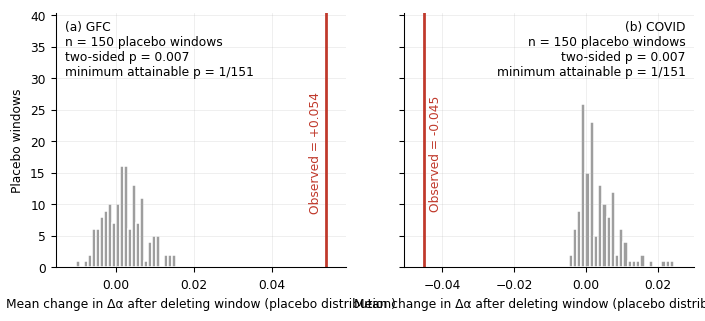

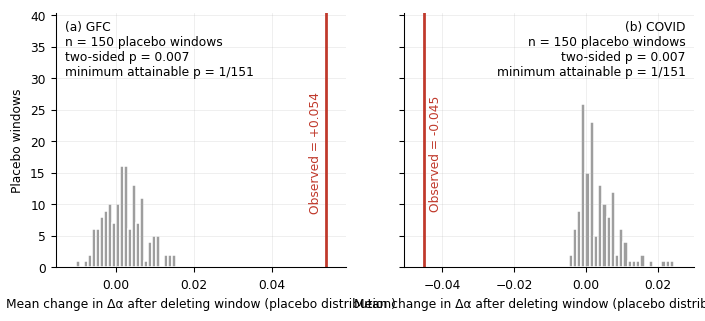

In [20]:
# ── Fig. 5 (paper): GFC and COVID deletion vs placebo windows (extended 2008-start sample) ──
def two_sided_p(plc_mean, real, K):
    c = plc_mean.mean()
    return (np.sum(np.abs(plc_mean - c) >= abs(real - c)) + 1) / (K + 1)

def plot_placebo_gfc_covid(name="fig5_placebo_gfc_covid"):
    fig, axs = plt.subplots(1, 2, figsize=(FIG_W_2COL, 3.0), sharey=True)
    for k, (ax, (nm, (pm, real))) in enumerate(zip(axs, plc_store.items())):
        Kp = len(pm); p2 = two_sided_p(pm, real, Kp)
        ax.hist(pm, bins=25, color="#9e9e9e", edgecolor="white")
        ax.axvline(real, color="#c0392b", lw=1.8)
        lo, hi = min(pm.min(), real), max(pm.max(), real); pad = .08 * (hi - lo); ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(0, ax.get_ylim()[1] * 1.55)                                    # head-room for the annotation block
        side_left = real > np.median(pm)                                           # put the note on the side away from the observed line
        ax.annotate(f"Observed = {real:+.3f}", xy=(real, .45), xycoords=("data", "axes fraction"), rotation=90, va="center",
                    ha="right" if real > np.median(pm) else "left", xytext=(-3 if real > np.median(pm) else 3, 0), textcoords="offset points", color="#c0392b")
        ax.text(.03 if side_left else .97, .97, f"({'ab'[k]}) {nm}\nn = {Kp} placebo windows\ntwo-sided p = {p2:.3f}\nminimum attainable p = 1/{Kp + 1}",
                transform=ax.transAxes, va="top", ha="left" if side_left else "right")
        ax.set_xlabel("Mean change in Δα after deleting window (placebo distribution)")
    axs[0].set_ylabel("Placebo windows"); savefig(fig, name); return fig
plot_placebo_gfc_covid()


In [21]:
# ═════════ §10c  FOUR-WAY DECOMPOSITION ON THE 2008-START SAMPLE, BY SCENARIO (slow) ═════════
DECOMP_SCEN = ["full", "ex-GFC", "ex-COVID"]
out, counts = {}, {}
for s in DECOMP_SCEN:
    with timed(f"surrogates {s}"):
        raw = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(
            delayed(surrogate_task)(t, remove_windows(returns_D[t], SCEN[s]).values, CFG["N_SURR"], CFG["IAAFT_ITERS"], CFG) for t in ELIG_D)
    rs = pd.DataFrame(raw).set_index("ticker").loc[ELIG_D]; rs["group"] = [GROUP[t] for t in rs.index]
    for k in ("shuffle", "iaaft", "phase"): rs[f"q_{k}"] = false_discovery_control(rs[f"p_{k}"].values, method="bh")
    savetable(rs, f"extended_surrogates_{s.replace('-', '_')}.csv")
    cm = pd.DataFrame({k: f(rs) for k, f in COMP.items()}); cm["group"] = rs["group"]
    rb = rng_for(f"decomp_boot_ext_{s}"); bt = np.array([agg_share(cm.iloc[rb.integers(0, len(cm), len(cm))]).values for _ in range(2000)])
    agg = agg_share(cm); mean_da = rs.delta_alpha.mean()
    out[s] = pd.DataFrame({"share_%": agg, "ci_lo": np.percentile(bt, 2.5, axis=0), "ci_hi": np.percentile(bt, 97.5, axis=0), "abs_delta_alpha": agg / 100 * mean_da})
    counts[s] = dict(mean_delta_alpha=mean_da, n_assets=len(rs), sig_temporal=int((rs.q_shuffle < .05).sum()),
                     sig_nonlinear=int((rs.q_iaaft < .05).sum()), sig_non_gaussian=int((rs.q_phase < .05).sum()))
dec_ext = pd.concat(out, axis=1); print("Four-way decomposition (aggregate shares, 95% bootstrap CI over assets; absolute = share × mean Δα):")
print(dec_ext.round(3).to_string()); savetable(dec_ext, "extended_decomposition_by_scenario.csv")
cnt = pd.DataFrame(counts).T; print("\nAssets passing BH q<0.05:"); print(cnt.round(3).to_string()); savetable(cnt, "extended_test_counts_by_scenario.csv")

[surrogates full] 328.7 s
[surrogates ex-GFC] 279.9 s
[surrogates ex-COVID] 387.8 s
Four-way decomposition (aggregate shares, 95% bootstrap CI over assets; absolute = share × mean Δα):
                              full                                  ex-GFC                                 ex-COVID                                
                           share_%   ci_lo   ci_hi abs_delta_alpha share_%   ci_lo   ci_hi abs_delta_alpha  share_%   ci_lo   ci_hi abs_delta_alpha
Gaussian/finite-size floor  40.514  38.349  42.898           0.201  42.475  40.453  44.687           0.233   42.952  40.704  45.333           0.194
Extra fat tails             39.052  34.222  44.295           0.194  25.002  21.175  29.436           0.137   41.255  35.725  47.309           0.186
Linear correlation          -2.463  -4.450  -0.659          -0.012   3.129   1.565   4.586           0.017   -4.616  -7.226  -2.155          -0.021
Nonlinear dependence        22.896  18.179  27.469           0.113  29.394 

,mean_delta_alpha,n_assets,sig_temporal,sig_nonlinear,sig_non_gaussian
full,0.495545,44.0,12.0,17.0,44.0
ex-GFC,0.549396,44.0,31.0,32.0,44.0
ex-COVID,0.450630,44.0,11.0,11.0,44.0


In [22]:
for name, (pm, real) in plc_store.items():
    p2 = (np.sum(np.abs(pm - pm.mean()) >= abs(real - pm.mean())) + 1) / (len(pm) + 1)
    print(f"{name}: change {real:+.3f}, placebo 5–95% [{pm.quantile(.05):+.3f}, {pm.quantile(.95):+.3f}], two-sided p = {p2:.3f}")

GFC: change +0.054, placebo 5–95% [-0.006, +0.011], two-sided p = 0.007
COVID: change -0.045, placebo 5–95% [-0.003, +0.012], two-sided p = 0.007


In [23]:
# ═════════ §11  SIMULATION: does the SHAPE of a volatility episode set the sign of its effect on Δα? ═════════
# NOTE (R1): this first run injects blocks of 133/302/132 *observations* although those numbers are CALENDAR days; section 11b reruns in trading days. Kept for comparison.
# Baseline: iid Student-t(4) returns, sd 1% (no clustering, no episodes). We inject volatility "episodes" (blocks whose returns
# are multiplied by m) and measure Δα with the same MF-DFA settings as the empirical work. Series length = the 2008-start sample.
N_SIM = int(os.environ.get("FLR_N_SIM", 100)); N_OBS = 4600

def sim_blocks(L, m, R, N, cfg, two=None, lens=(302, 132), fixed_pos=None):
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS", "SCALE_MIN", "SCALE_MAX", "N_SCALES", "POLY_ORD", "OVERLAP"))
    rx = np.random.default_rng(np.random.SeedSequence([cfg["SEED"], 101]))      # same base series for every (L, m)  → paired comparison
    rp = np.random.default_rng(np.random.SeedSequence([cfg["SEED"], 202]))      # block position
    out = np.empty(R)
    for i in range(R):
        x = 0.01 * rx.standard_t(4, N) / np.sqrt(2)
        if two is None:
            pos = rp.integers(int(.2 * N), int(.8 * N) - max(L, 1)) if fixed_pos is None else int(fixed_pos * N)
            if L > 0: x[pos:pos + L] *= m
        else:                                                                      # two = (gfc_mult, covid_mult), lens = (gfc_len, covid_len)
            if two[0]: x[int(.05 * N):int(.05 * N) + lens[0]] *= two[0]            # GFC-like block, early
            if two[1]: x[int(.80 * N):int(.80 * N) + lens[1]] *= two[1]            # COVID-like block, late
        _, _, hq = mfdfa_fast(x, q, smin, smax, ns, po, ov); out[i] = delta_alpha(q, hq)
    return out

LS, MS = [0, 10, 20, 40, 60, 90, 133, 200, 300, 450], [3, 6]
jobs = [(L, m) for m in MS for L in LS]
CASES = {"none": (0, 0), "GFC-like only (302d, ×3)": (3, 0), "COVID-like only (132d, ×6)": (0, 6), "both": (3, 6)}
with timed("block simulation"):
    res_s = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(sim_blocks)(L, m, N_SIM, N_OBS, CFG) for L, m in jobs)
    res_t = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(sim_blocks)(0, 0, N_SIM, N_OBS, CFG, two) for two in CASES.values())

sweep = {}
for (L, m), r in zip(jobs, res_s): sweep[(m, L)] = r
base = sweep[(MS[0], 0)]
rows = [dict(multiplier=m, block_days=L, mean_delta_alpha=r.mean(), change_vs_no_block=(r - base).mean(),
             se=(r - base).std(ddof=1) / np.sqrt(len(r))) for (m, L), r in sweep.items()]
sweep_df = pd.DataFrame(rows); savetable(sweep_df, "simulation_block_length.csv", index=False)
print("Δα change vs no block, by block length (paired, iid-t baseline):")
print(sweep_df.pivot(index="block_days", columns="multiplier", values="change_vs_no_block").round(3).to_string())

d = dict(zip(CASES, res_t)); two_tbl = pd.Series({k: v.mean() for k, v in d.items()}, name="mean_delta_alpha")
n_, g_, c_, b_ = (d[k] for k in CASES)
inter = pd.DataFrame({"effect of adding GFC-like block": [(g_ - n_).mean(), (b_ - c_).mean()],
                      "effect of adding COVID-like block": [(c_ - n_).mean(), (b_ - g_).mean()]}, index=["other episode absent", "other episode present"])
print("\nTwo-episode interaction (mean Δα):"); print(two_tbl.round(3).to_string()); print(inter.round(3).to_string())
savetable(two_tbl.to_frame(), "simulation_two_episodes.csv"); savetable(inter, "simulation_interaction.csv")

# Fig. 7 is drawn in section 11b (trading-day run).

[block simulation] 11.9 s
Δα change vs no block, by block length (paired, iid-t baseline):
multiplier      3      6
block_days              
0           0.000  0.000
10          0.021  0.103
20          0.048  0.185
40          0.075  0.230
60          0.097  0.234
90          0.113  0.217
133         0.109  0.178
200         0.089  0.129
300         0.067  0.089
450         0.047  0.057

Two-episode interaction (mean Δα):
none                          0.352
GFC-like only (302d, ×3)      0.411
COVID-like only (132d, ×6)    0.541
both                          0.518
                       effect of adding GFC-like block  effect of adding COVID-like block
other episode absent                             0.059                              0.189
other episode present                           -0.023                              0.107


,effect of adding GFC-like block,effect of adding COVID-like block
other episode absent,0.058832,0.188879
other episode present,-0.023045,0.107003


## REVISION section
New analyses requested for the revision. Results: `outputs/revision/tables/`, revised figures: `flr_run/figures/revised/`. Every new random task uses a new RNG name, so all earlier numbers are unchanged.

In [24]:
# ═════════════════════════════ REVISION  setup ═════════════════════════════
# New results go to outputs/revision/ ; every new random task uses a NEW rng name, so no existing number can move.
(REV / "tables").mkdir(parents=True, exist_ok=True)
def rev_table(df, name, **kw): df.to_csv(REV / "tables" / name, **kw); return df
CHANGES = []                                         # (item, quantity, old, new): becomes change_log.csv at the end
def log_change(item, quantity, old, new): CHANGES.append(dict(item=item, quantity=quantity, old=old, new=new))
print("revision outputs ->", REV)


revision outputs -> outputs\revision


COVID window: 132 calendar days = 93 trading days | GFC window: 302 calendar days = 209 trading days (counted on AAPL)
[block simulation (trading days)] 15.1 s
Δα change vs no block, trading-day lengths (paired, iid-t baseline):
multiplier      3      6
block_obs               
0           0.000  0.000
10          0.021  0.103
20          0.048  0.185
40          0.075  0.230
60          0.097  0.234
90          0.113  0.217
93          0.112  0.215
150         0.102  0.158
209         0.087  0.125
300         0.067  0.089
450         0.047  0.057
none                            0.352
GFC-like only (209 obs, ×3)     0.429
COVID-like only (93 obs, ×6)    0.569
both                            0.545
                       effect of adding GFC-like block  effect of adding COVID-like block
other episode absent                             0.077                              0.217
other episode present                           -0.025                              0.115

Reconciliation of the C

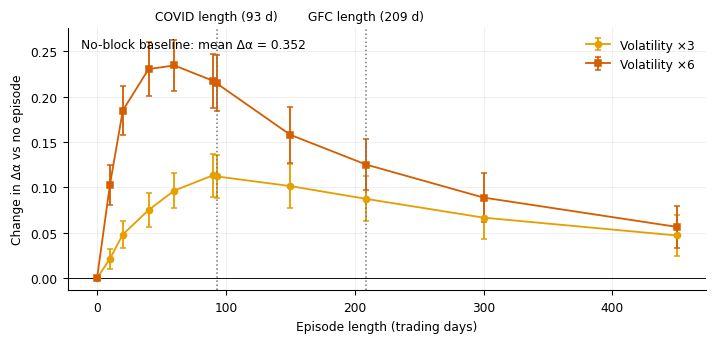

Error bars: 95% CI = ±1.96 × SE of the paired change in Δα over 100 replications (SE = SD of the paired difference / sqrt(100)). Dotted lines: trading days in the real windows (93 for 2020-02-19 to 2020-06-30, 209 for 2008-09-01 to 2009-06-30). Baseline: iid Student-t(4), N = 4600, mean Δα = 0.352.


In [25]:
# ═════════ §11b  SIMULATION RERUN WITH TRADING-DAY BLOCK LENGTHS  (REVISION items 10, 11) ═════════
# The first run (section 11, kept above and in simulation_*.csv) injected blocks of 133 / 302 / 132 OBSERVATIONS, but those are CALENDAR-day spans
# of the real windows (132 and 302 days). The simulated series are indexed by trading days, so the matching lengths are the numbers of trading days.
_eq = next(t for t in ELIG_D if GROUP[t] in ("Tech", "Financials", "Health/Cons", "Energy/Ind"))
_idx = returns_D[_eq].index
def n_obs_between(a, b): return int(((_idx >= pd.Timestamp(a)) & (_idx <= pd.Timestamp(b))).sum())
COVID_TD, GFC_TD = n_obs_between(*EPISODES_D["COVID"]), n_obs_between(*EPISODES_D["GFC"])
COVID_CAL, GFC_CAL = (pd.Timestamp(EPISODES_D["COVID"][1]) - pd.Timestamp(EPISODES_D["COVID"][0])).days, (pd.Timestamp(EPISODES_D["GFC"][1]) - pd.Timestamp(EPISODES_D["GFC"][0])).days
print(f"COVID window: {COVID_CAL} calendar days = {COVID_TD} trading days | GFC window: {GFC_CAL} calendar days = {GFC_TD} trading days (counted on {_eq})")

LS_TD = sorted({0, 10, 20, 40, 60, 90, COVID_TD, 150, GFC_TD, 300, 450})
jobs_td = [(L, m) for m in MS for L in LS_TD]
CASES_TD = {"none": (0, 0), f"GFC-like only ({GFC_TD} obs, ×3)": (3, 0), f"COVID-like only ({COVID_TD} obs, ×6)": (0, 6), "both": (3, 6)}
with timed("block simulation (trading days)"):
    res_s_td = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(sim_blocks)(L, m, N_SIM, N_OBS, CFG) for L, m in jobs_td)
    res_t_td = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(sim_blocks)(0, 0, N_SIM, N_OBS, CFG, two, (GFC_TD, COVID_TD)) for two in CASES_TD.values())
sweep_td = {(m, L): r for (L, m), r in zip(jobs_td, res_s_td)}
base_td = sweep_td[(MS[0], 0)]
sweep_td_df = pd.DataFrame([dict(multiplier=m, block_obs=L, mean_delta_alpha=r.mean(), change_vs_no_block=(r - base_td).mean(),
                                 sd_change=(r - base_td).std(ddof=1), se=(r - base_td).std(ddof=1) / np.sqrt(len(r)), n_rep=len(r)) for (m, L), r in sweep_td.items()])
rev_table(sweep_td_df, "simulation_block_length_trading_days.csv", index=False)
print("Δα change vs no block, trading-day lengths (paired, iid-t baseline):"); print(sweep_td_df.pivot(index="block_obs", columns="multiplier", values="change_vs_no_block").round(3).to_string())
d_td = dict(zip(CASES_TD, res_t_td)); n2, g2, c2, b2 = (d_td[k] for k in CASES_TD)
two_td = pd.Series({k: v.mean() for k, v in d_td.items()}, name="mean_delta_alpha")
inter_td = pd.DataFrame({"effect of adding GFC-like block": [(g2 - n2).mean(), (b2 - c2).mean()], "effect of adding COVID-like block": [(c2 - n2).mean(), (b2 - g2).mean()]},
                        index=["other episode absent", "other episode present"])
rev_table(two_td.to_frame(), "simulation_two_episodes_trading_days.csv"); rev_table(inter_td, "simulation_interaction_trading_days.csv")
print(two_td.round(3).to_string()); print(inter_td.round(3).to_string())

# ── Item 11: why is a COVID-length x6 block +0.178 in one place and +0.189 in another? ──
# (i) Fig. 7 sweep: block of 133 at a RANDOM position (20-80% of the series), paired with the same base series.
# (ii) two-episode table: block of 132 at the FIXED position 0.80 N (late in the sample). Same base series, same multiplier.
# They differ by block position (random vs fixed late) and by one observation (133 vs 132); nothing else (same seeds for the base series).
base0 = sim_blocks(0, 0, N_SIM, N_OBS, CFG)
diag = []
for lab, L, fp in (("Fig. 7 sweep: L=133, random position", 133, None), ("L=133 at fixed position 0.80 N", 133, .8), ("two-episode table: L=132 at fixed position 0.80 N", 132, .8)):
    diag.append(dict(setting=lab, change_vs_no_block=float((sim_blocks(L, 6, N_SIM, N_OBS, CFG, None, fixed_pos=fp) - base0).mean())))
diag = pd.DataFrame(diag).set_index("setting"); rev_table(diag, "simulation_covid_x6_reconciliation.csv"); print("\nReconciliation of the COVID-length x6 numbers:"); print(diag.round(3).to_string())

# old (calendar-day) vs new (trading-day) comparison
old_new = pd.DataFrame({"old (calendar-day lengths)": two_tbl, "new (trading-day lengths)": two_td.set_axis(list(two_tbl.index))}); rev_table(old_new, "simulation_old_vs_new.csv"); print(old_new.round(3).to_string())

# ── Fig. 7 (paper): lines come from the SAME constants the simulation used ──
def plot_simulation(sweep_df, ref_lines, base_mean, name="fig7_simulation_block_length"):
    fig, ax = plt.subplots(figsize=(FIG_W_2COL, 3.1)); cols = {3: "#E69F00", 6: "#D55E00"}; mk = {3: "o", 6: "s"}
    for m in MS:
        s = sweep_df[sweep_df.multiplier == m]
        ax.errorbar(s.block_obs, s.change_vs_no_block, yerr=1.96 * s.se, marker=mk[m], ms=4, color=cols[m], capsize=2, label=f"Volatility ×{m}")
    for L_, lab in ref_lines:
        ax.axvline(L_, color="#777", ls=":", lw=1)
        ax.annotate(f"{lab} ({L_} d)", xy=(L_, 1.0), xycoords=("data", "axes fraction"), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)   # above the axes: never over the data
    ax.axhline(0, color="k", lw=.6); ax.set_xlabel("Episode length (trading days)"); ax.set_ylabel("Change in Δα vs no episode")
    ax.text(.02, .96, f"No-block baseline: mean Δα = {base_mean:.3f}", transform=ax.transAxes, va="top")
    ax.legend(loc="upper right", frameon=False); savefig(fig, name); return fig
plot_simulation(sweep_td_df, [(COVID_TD, "COVID length"), (GFC_TD, "GFC length")], float(base_td.mean()))
fig7_caption = (f"Error bars: 95% CI = ±1.96 × SE of the paired change in Δα over {N_SIM} replications (SE = SD of the paired difference / sqrt({N_SIM})). "
                f"Dotted lines: trading days in the real windows ({COVID_TD} for 2020-02-19 to 2020-06-30, {GFC_TD} for 2008-09-01 to 2009-06-30). "
                f"Baseline: iid Student-t(4), N = {N_OBS}, mean Δα = {base_td.mean():.3f}.")
(REV / "tables" / "fig7_caption.txt").write_text(fig7_caption, encoding="utf-8"); print(fig7_caption)
log_change("10", f"COVID-length block (×6): change in Δα (random position) [old L=133 calendar -> new L={COVID_TD} trading]", 0.178, float(sweep_td_df.query(f"multiplier==6 and block_obs=={COVID_TD}").change_vs_no_block.iloc[0]))
log_change("10", f"COVID-only (fixed late position, ×6) [old L=132 -> new L={COVID_TD}]", 0.189, float(inter_td.iloc[0, 1]))
log_change("10", f"GFC-only (×3) [old L=302 -> new L={GFC_TD}]", 0.059, float(inter_td.iloc[0, 0]))


In [26]:
# ═════════ REVISION item 1: i.i.d. Gaussian benchmark (same estimator settings as everywhere else) ═════════
# Variance matching: MF-DFA width is invariant to the scale of the series (checked below), so "matched variance" = sd 1%, as in the Student-t(4) simulation.
# No Gaussian generator exists in this notebook (the cumulant-index code was not provided), so a plain N(0, sd^2) generator is used.
B_G = int(os.environ.get("FLR_B_GAUSS", 500))
def _iid_one(N, kind, name, cfg):
    r = np.random.default_rng(np.random.SeedSequence([cfg["SEED"], zlib.crc32(name.encode())]))
    z = r.standard_normal(N) if kind == "gauss" else r.standard_t(4, N) / np.sqrt(2)
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS", "SCALE_MIN", "SCALE_MAX", "N_SCALES", "POLY_ORD", "OVERLAP"))
    _, _, hq = mfdfa_fast(0.01 * z, q, smin, smax, ns, po, ov); return delta_alpha(q, hq)

_z = rng_for("gauss_scale_check").standard_normal(2000)
assert abs(da_of(0.01 * _z)[0] - da_of(7.3 * _z)[0]) < 1e-9, "width should be scale invariant"

rows_g = []
with timed("iid benchmarks"):
    for N in (4091, 4600):
        for kind, lab in (("gauss", "i.i.d. Gaussian"), ("t4", "i.i.d. Student-t(4)")):
            w = np.array(Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(_iid_one)(N, kind, f"iid_{kind}_{N}_{i}", CFG) for i in range(B_G)))
            rows_g.append(dict(benchmark=lab, N=N, B=B_G, mean_width=w.mean(), sd=w.std(ddof=1), p025=np.percentile(w, 2.5), p975=np.percentile(w, 97.5)))
bench = pd.DataFrame(rows_g)
pr_main = float(res["phase_mean"].mean())
pr_ext = np.nan
_f = TABLES / "extended_surrogates_full.csv"
if _f.exists(): pr_ext = float(pd.read_csv(_f, index_col=0)["phase_mean"].mean())
ref = pd.DataFrame([dict(benchmark="phase-randomized mean (observed assets, main sample, 50 assets)", N=4091, B=CFG["N_SURR"], mean_width=pr_main),
                    dict(benchmark="phase-randomized mean (observed assets, extended sample, 44 assets)", N=4600, B=CFG["N_SURR"], mean_width=pr_ext),
                    dict(benchmark="i.i.d. Student-t(4), previous run (section 11 'none', N_SIM replications)", N=4600, B=N_SIM, mean_width=float(two_tbl["none"]))])
bench_all = pd.concat([bench, ref], ignore_index=True); rev_table(bench_all, "iid_gaussian_benchmark.csv", index=False)
print(bench_all.round(3).to_string(index=False))
log_change("1", "i.i.d. Student-t(4) mean width, N=4600", 0.352, float(bench.query("benchmark=='i.i.d. Student-t(4)' and N==4600").mean_width.iloc[0]))
log_change("1", "i.i.d. Gaussian mean width, N=4091 (new)", np.nan, float(bench.query("benchmark=='i.i.d. Gaussian' and N==4091").mean_width.iloc[0]))
log_change("1", "i.i.d. Gaussian mean width, N=4600 (new)", np.nan, float(bench.query("benchmark=='i.i.d. Gaussian' and N==4600").mean_width.iloc[0]))


[iid benchmarks] 5.6 s
                                                                benchmark    N   B  mean_width    sd  p025  p975
                                                          i.i.d. Gaussian 4091 500       0.218 0.063 0.085 0.331
                                                      i.i.d. Student-t(4) 4091 500       0.352 0.093 0.190 0.542
                                                          i.i.d. Gaussian 4600 500       0.218 0.063 0.090 0.334
                                                      i.i.d. Student-t(4) 4600 500       0.348 0.098 0.188 0.589
          phase-randomized mean (observed assets, main sample, 50 assets) 4091 500       0.231   NaN   NaN   NaN
      phase-randomized mean (observed assets, extended sample, 44 assets) 4600 500       0.201   NaN   NaN   NaN
i.i.d. Student-t(4), previous run (section 11 'none', N_SIM replications) 4600 100       0.352   NaN   NaN   NaN


In [27]:
# ═════════ REVISION item 2: order dependence of the sequential contrasts ═════════
# The four states per asset are the mean widths of the PR, SH, IAAFT surrogates and the observed width. A chain visits the four states in some order;
# the step that lands on a state is its "contrast" (first state: its level; later: difference to the predecessor). Shares are ratios of cross-asset sums
# (as in the paper). All 24 orderings are shown. Only chains that END at "obs" telescope to 100%, so the Shapley-style average uses those 3! = 6 orderings
# (average marginal step per state). CAVEAT: the four states are not a full factorial design (e.g. no Gaussian series with nonlinear dependence),
# so non-canonical orders mix in steps that remove a property; read them as an order-sensitivity band, not as causal attribution.
import itertools
STN = ["PR", "SH", "IA", "OBS"]
def _states(r): return pd.DataFrame({"PR": r["phase_mean"], "SH": r["shuffle_mean"], "IA": r["iaaft_mean"], "OBS": r["delta_alpha"]})
def _chain(S, o):
    """S: Series of cross-asset sums per state; returns dict state -> share (%) of the aggregate observed width."""
    tot, prev, out = S["OBS"], 0.0, {}
    for s in o: out[s] = 100 * (S[s] - prev) / tot; prev = S[s]
    return out
ALL24 = list(itertools.permutations(STN)); OBS_LAST = [o for o in ALL24 if o[-1] == "OBS"]
CANON = ("PR", "SH", "IA", "OBS")
def _step_name(o, s): i = o.index(s); return s if i == 0 else f"{s}-{o[i-1]}"
order_summaries = {}
for tag, rr in (("full", res), ("ex-COVID", res_x)):
    V = _states(rr); S = V.sum()
    long = pd.DataFrame([dict(ordering=" > ".join(o), position=i + 1, contrast=_step_name(o, s), share_pct=_chain(S, o)[s],
                              sum_of_shares=sum(_chain(S, o).values()), ends_at_obs=o[-1] == "OBS") for o in ALL24 for i, s in enumerate(o)])
    rev_table(long, f"order_dependence_all24_{tag}.csv", index=False)
    rb_o = rng_for(f"order_boot_{tag}"); BO = 2000; Vn = V.values; nA = len(V)
    boot_sh, boot_rng, boot_can = [], [], []
    for _ in range(BO):
        Sb = pd.Series(Vn[rb_o.integers(0, nA, nA)].sum(axis=0), index=STN)
        M = pd.DataFrame([_chain(Sb, o) for o in OBS_LAST])           # 6 orderings x 4 states
        boot_sh.append(M.mean().values); boot_rng.append((M.max() - M.min()).values); boot_can.append(pd.Series(_chain(Sb, CANON)).values)
    boot_sh, boot_rng, boot_can = map(np.array, (boot_sh, boot_rng, boot_can))
    M0 = pd.DataFrame([_chain(S, o) for o in OBS_LAST], index=[" > ".join(o) for o in OBS_LAST])
    summ = pd.DataFrame({"canonical PR>SH>IA>OBS (%)": pd.Series(_chain(S, CANON)), "min over 6 orders (%)": M0.min(), "max over 6 orders (%)": M0.max(),
                         "range (pp)": M0.max() - M0.min(), "Shapley-style mean (%)": M0.mean(),
                         "Shapley CI lo": np.percentile(boot_sh, 2.5, axis=0), "Shapley CI hi": np.percentile(boot_sh, 97.5, axis=0),
                         "range CI lo": np.percentile(boot_rng, 2.5, axis=0), "range CI hi": np.percentile(boot_rng, 97.5, axis=0),
                         "canonical CI lo": np.percentile(boot_can, 2.5, axis=0), "canonical CI hi": np.percentile(boot_can, 97.5, axis=0)}).loc[STN]
    order_summaries[tag] = summ; rev_table(summ, f"order_dependence_summary_{tag}.csv")
    print(f"\n[{tag}] share of aggregate width by state, canonical chain vs all 6 chains that end at obs ({BO} asset-level bootstrap draws):"); print(summ.round(1).to_string())
    print(f"[{tag}] 24 orderings written to order_dependence_all24_{tag}.csv (chains not ending at obs sum to {sorted(set(long.query('~ends_at_obs').sum_of_shares.round(1)))[:3]}... % because they stop at another state)")
log_change("2", "canonical shares full sample: PR / SH-PR / IA-SH / obs-IA (%)", "42.1 / 26.0 / 2.0 / 29.9", " / ".join(f"{v:.1f}" for v in order_summaries["full"]["canonical PR>SH>IA>OBS (%)"].values))



[full] share of aggregate width by state, canonical chain vs all 6 chains that end at obs (2000 asset-level bootstrap draws):
     canonical PR>SH>IA>OBS (%)  min over 6 orders (%)  max over 6 orders (%)  range (pp)  Shapley-style mean (%)  Shapley CI lo  Shapley CI hi  range CI lo  range CI hi  canonical CI lo  canonical CI hi
PR                         42.1                  -28.0                   42.1        70.1                    -4.0           -6.1           -2.0         66.3         74.1             40.3             44.2
SH                         26.0                   -2.0                   68.1        70.1                    30.7           27.7           34.0         66.3         74.1             22.3             30.0
IA                          2.0                    2.0                   70.1        68.1                    33.4           31.3           35.5         63.6         73.1              0.3              3.6
OBS                        29.9                   29.9   

In [28]:
# ═════════ REVISION item 3: CL=F on 2020-04-20 (negative settlement) ═════════
# What the code does (section 1): non-positive prices are DROPPED BEFORE the log, then diff() -> one return spans TWO trading days
# (last positive close -> next positive close). Returns are NOT computed first with NaNs dropped afterwards.
p_cl = prices_A["CL=F"].dropna(); neg_cl = p_cl[p_cl <= 0]
r_a = returns_A["CL=F"]
info = dict(n_returns_as_implemented=len(r_a), n_nonpositive_prices=len(neg_cl))
if len(neg_cl):
    d_neg = neg_cl.index[0]; d_prev = p_cl.index[p_cl.index < d_neg][-1]; d_next = p_cl.index[p_cl.index > d_neg][0]
    info.update(negative_price_date=str(d_neg.date()), negative_price=float(neg_cl.iloc[0]), spanning_return_from=str(d_prev.date()), spanning_return_to=str(d_next.date()),
                spanning_return_value=float(r_a.loc[d_next]), calendar_days_spanned=(d_next - d_prev).days,
                undefined_returns_if_logs_first="2 (into and out of the negative price)", n_returns_if_both_dropped=len(r_a) - 1)
print("CL=F handling:"); [print(f"  {k}: {v}") for k, v in info.items()]

def _wd(r): return da_of(r.values)[0], da_of(drop_window(r, *EXCL).values)[0]
variants = {"(a) as implemented (one return spans two days)": r_a}
if len(neg_cl): variants["(b) drop the spanning return (both affected returns removed)"] = r_a.drop(d_next)
others = [t for t in TICKERS_A if t != "CL=F"]
oth_full, oth_ex = res.loc[others, "delta_alpha"], cmp_.loc[others, "ex_covid"]
rows_cl = []
for lab, r in list(variants.items()) + [("(c) exclude CL=F entirely", None)]:
    if r is not None: w_f, w_x = _wd(r); n_ret = len(r)
    else: w_f = w_x = np.nan; n_ret = 0
    full_all = pd.concat([oth_full, pd.Series({"CL=F": w_f})]).dropna(); ex_all = pd.concat([oth_ex, pd.Series({"CL=F": w_x})]).dropna()
    com = [t for t in ("GC=F", "SI=F", "CL=F") if t in full_all.index]
    rows_cl.append(dict(variant=lab, n_returns_CLF=n_ret, width_CLF=w_f, width_CLF_ex_covid=w_x, covid_change_CLF=w_x - w_f,
                        mean_width_all=full_all.mean(), n_assets=len(full_all), covid_change_all=(ex_all - full_all).mean(),
                        mean_width_commodities=full_all[com].mean(), covid_change_commodities=(ex_all[com] - full_all[com]).mean()))
clf = pd.DataFrame(rows_cl); rev_table(clf, "clf_sensitivity.csv", index=False); print(clf.round(4).to_string(index=False))
assert abs(clf.iloc[0].width_CLF - res.loc["CL=F", "delta_alpha"]) < 1e-12, "variant (a) must reproduce the main result"
pd.Series(info).to_csv(REV / "tables" / "clf_handling_facts.csv", header=["value"])
log_change("3", "COVID-deletion change, commodities (as implemented)", -0.087, float(clf.iloc[0].covid_change_commodities))
log_change("3", "COVID-deletion change, commodities (exclude CL=F)", np.nan, float(clf.iloc[-1].covid_change_commodities))


CL=F handling:
  n_returns_as_implemented: 4090
  n_nonpositive_prices: 1
  negative_price_date: 2020-04-20
  negative_price: -37.630001068115234
  spanning_return_from: 2020-04-17
  spanning_return_to: 2020-04-21
  spanning_return_value: -0.6016757792529508
  calendar_days_spanned: 4
  undefined_returns_if_logs_first: 2 (into and out of the negative price)
  n_returns_if_both_dropped: 4089
                                                     variant  n_returns_CLF  width_CLF  width_CLF_ex_covid  covid_change_CLF  mean_width_all  n_assets  covid_change_all  mean_width_commodities  covid_change_commodities
              (a) as implemented (one return spans two days)           4090     0.6656               0.399           -0.2666          0.5481        50           -0.1032                  0.5687                   -0.0873
(b) drop the spanning return (both affected returns removed)           4089     0.5954               0.399           -0.1964          0.5467        50           -0.1018

In [29]:
# ═════════ REVISION items 4, 5, 6: sampling, end date, sector coverage ═════════
# ── 4: per-asset first/last date, number of returns, and how each series is sampled ──
rows_a = []
for t in TICKERS_A:
    r = returns_A[t]; gaps = np.diff(r.index.values).astype("timedelta64[D]").astype(int); wk = int((r.index.dayofweek >= 5).sum())
    rows_a.append(dict(ticker=t, group=GROUP[t], first_return=str(r.index[0].date()), last_return=str(r.index[-1].date()), n_returns=len(r),
                       weekend_returns=wk, median_gap_days=float(np.median(gaps)), max_gap_days=int(gaps.max()),
                       calendar_days_spanned=(r.index[-1] - r.index[0]).days,
                       sampling="7-day calendar" if wk / len(r) > .2 else "trading days (Mon-Fri)"))
audit = pd.DataFrame(rows_a).set_index("ticker"); rev_table(audit, "sampling_audit.csv"); print(audit.to_string())
modal = int(audit["n_returns"].mode().iloc[0]); exc = audit[audit["n_returns"] != modal]
print(f"\n'{modal} returns' holds for {int((audit.n_returns == modal).sum())} of {len(audit)} assets; exceptions ({len(exc)}):")
print(exc[["group", "first_return", "n_returns", "sampling"]].to_string())
for t in ("BTC-USD", "ETH-USD"):
    a = audit.loc[t]; print(f"{t}: first return {a.first_return}, {a.n_returns} returns over {a.calendar_days_spanned} calendar days, {a.weekend_returns} on weekends -> {a.sampling}. "
                            f"Series start when Yahoo's price history starts (not by choice of START_A={CFG['START_A']}).")
# does weekend sampling change widths?  Re-estimate crypto on weekdays only (Fri->Mon return spans 3 days, like equities)
rows_c = []
for t in [t for t in TICKERS_A if GROUP[t] == "Crypto"]:
    p = prices_A[t].dropna(); p = p[p > 0]; r7 = np.log(p).diff().dropna(); r5 = np.log(p[p.index.dayofweek < 5]).diff().dropna()
    f7, x7 = _wd(r7); f5, x5 = _wd(r5)
    n_cov7 = int(((r7.index >= pd.Timestamp(EXCL[0])) & (r7.index <= pd.Timestamp(EXCL[1]))).sum()); n_cov5 = int(((r5.index >= pd.Timestamp(EXCL[0])) & (r5.index <= pd.Timestamp(EXCL[1]))).sum())
    rows_c.append(dict(ticker=t, n_7day=len(r7), n_weekday=len(r5), width_7day=f7, width_weekday=f5, covid_change_7day=x7 - f7, covid_change_weekday=x5 - f5,
                       covid_obs_removed_7day=n_cov7, covid_obs_removed_weekday=n_cov5))
crypto_sens = pd.DataFrame(rows_c).set_index("ticker"); rev_table(crypto_sens, "crypto_sampling_sensitivity.csv"); print("\nCrypto: 7-day vs weekday-only sampling:"); print(crypto_sens.round(3).to_string())
eq_removed = int(((returns_A["AAPL"].index >= pd.Timestamp(EXCL[0])) & (returns_A["AAPL"].index <= pd.Timestamp(EXCL[1]))).sum())
print(f"COVID deletion removes {eq_removed} equity returns but {int(crypto_sens.covid_obs_removed_7day.iloc[0])} crypto returns (calendar window of {(pd.Timestamp(EXCL[1]) - pd.Timestamp(EXCL[0])).days} days).")

# ── 5: end date ──
man_ = _manifest(); fn_cl = [k for k in man_ if k.startswith("AAPL_") and k.endswith(CFG["END_A"] + ".csv")]
end_chk = pd.Series(dict(config_END_A=CFG["END_A"], END_A_weekday=pd.Timestamp(CFG["END_A"]).day_name(), yfinance_end_is="exclusive",
                         last_return_equities=audit.loc[audit.group != "Crypto", "last_return"].max(), last_return_crypto=audit.loc[audit.group == "Crypto", "last_return"].max(),
                         manifest_last_AAPL=man_[fn_cl[0]]["last"] if fn_cl else "n/a",
                         config_END_C=CFG["END_C"], last_obs_scaling_series=max(v[1] for v in periods.values())), name="value")
rev_table(end_chk.to_frame(), "end_date_check.csv"); print("\nEnd-date check:"); print(end_chk.to_string())
print(f"-> data end on {end_chk.last_return_equities} (last trading day); the config END_A={CFG['END_A']} is the exclusive download bound. Say: 'data through {end_chk.last_return_equities}'.")

# ── 6: sector coverage (GICS sectors typed by hand from the current GICS structure: verify before citing) ──
GICS = {"AAPL": "Information Technology", "MSFT": "Information Technology", "NVDA": "Information Technology", "AMD": "Information Technology", "INTC": "Information Technology",
        "GOOG": "Communication Services", "META": "Communication Services", "NFLX": "Communication Services", "AMZN": "Consumer Discretionary", "TSLA": "Consumer Discretionary",
        "JPM": "Financials", "BAC": "Financials", "GS": "Financials", "MS": "Financials", "WFC": "Financials", "BLK": "Financials", "C": "Financials", "AXP": "Financials", "V": "Financials", "MA": "Financials",
        "JNJ": "Health Care", "PFE": "Health Care", "UNH": "Health Care", "MRK": "Health Care", "ABBV": "Health Care",
        "PG": "Consumer Staples", "KO": "Consumer Staples", "PEP": "Consumer Staples", "WMT": "Consumer Staples", "COST": "Consumer Staples",
        "XOM": "Energy", "CVX": "Energy", "COP": "Energy", "BA": "Industrials", "CAT": "Industrials", "GE": "Industrials", "HON": "Industrials", "LMT": "Industrials", "RTX": "Industrials", "UPS": "Industrials"}
equities = [t for g in ("Tech", "Financials", "Health/Cons", "Energy/Ind") for t in TICKERS_A if GROUP[t] == g]
assert set(equities) == set(GICS), set(equities) ^ set(GICS)
ALL11 = ["Communication Services", "Consumer Discretionary", "Consumer Staples", "Energy", "Financials", "Health Care", "Industrials", "Information Technology", "Materials", "Real Estate", "Utilities"]
gics_cnt = pd.Series(GICS).value_counts().reindex(ALL11).fillna(0).astype(int); rev_table(gics_cnt.to_frame("n_equities"), "gics_sector_counts.csv"); print("\nGICS sector counts of the 40 equities:"); print(gics_cnt.to_string())
print("Sectors with NO name:", [s for s in ALL11 if gics_cnt[s] == 0], f"-> {int((gics_cnt > 0).sum())} of 11 GICS sectors are covered.")


               group first_return last_return  n_returns  weekend_returns  median_gap_days  max_gap_days  calendar_days_spanned                sampling
ticker                                                                                                                                                 
AAPL            Tech   2010-01-05  2026-04-10       4091                0              1.0             5                   5939  trading days (Mon-Fri)
MSFT            Tech   2010-01-05  2026-04-10       4091                0              1.0             5                   5939  trading days (Mon-Fri)
GOOG            Tech   2010-01-05  2026-04-10       4091                0              1.0             5                   5939  trading days (Mon-Fri)
AMZN            Tech   2010-01-05  2026-04-10       4091                0              1.0             5                   5939  trading days (Mon-Fri)
NVDA            Tech   2010-01-05  2026-04-10       4091                0              1

In [30]:
# ═════════ REVISION items 7 and 8: singularity-spectrum sanity, q-grid / smoothing / range ═════════
QF = [float(q) for q in range(-30, 31)]                                   # step-1 grid; h(q) is estimated per q, so any coarser grid is a slice of this
with timed("h(q) on the step-1 grid"):
    HQ1 = pd.DataFrame({t: mfdfa_fast(returns_A[t].values, QF, CFG["SCALE_MIN"], CFG["SCALE_MAX"], CFG["N_SCALES"], CFG["POLY_ORD"], CFG["OVERLAP"])[2] for t in TICKERS_A}, index=QF).T
def width_grid(q_lo, q_hi, step, method):
    q = np.arange(q_lo, q_hi + 1e-9, step); cols = [QF.index(float(v)) for v in q]
    return pd.Series({t: delta_alpha(q, HQ1.loc[t].values[cols], method) for t in TICKERS_A})
w_base = width_grid(-30, 30, 5, "sg")
assert np.allclose(w_base.values, res.loc[TICKERS_A, "delta_alpha"].values, atol=1e-12), "step-5 slice must reproduce the main widths"

# ── 7a: does a single segment dominate F_q at large |q|?  weights w_i = rms_i^q / sum_j rms_j^q ──
def dom(x, s, q):
    rms = segment_rms(x, s, CFG["POLY_ORD"], CFG["OVERLAP"]); lw = q * np.log(rms); w = np.exp(lw - np.logaddexp.reduce(lw)); return w.max(), 1 / np.sum(w ** 2), len(rms)
rows_d = []
for s in (100, 800):
    for q in (-30, -20, -15, -10, -5, 5, 10, 15, 20, 30):
        v = np.array([dom(returns_A[t].values, s, q) for t in TICKERS_A])
        rows_d.append(dict(scale=s, q=q, mean_max_weight=v[:, 0].mean(), mean_effective_n_segments=v[:, 1].mean(), n_segments=int(v[:, 2].mean())))
dom_df = pd.DataFrame(rows_d); rev_table(dom_df, "spectrum_dominance_by_q.csv", index=False)
print("Weight of the single largest segment in F_q (mean over assets); effective number of segments = 1/sum(w^2):"); print(dom_df.round(3).to_string(index=False))
alpha5 = pd.DataFrame({t: spectrum(CFG["Q_VALS"], HQ1.loc[t].values[[QF.index(v) for v in CFG["Q_VALS"]]])[1] for t in TICKERS_A}, index=CFG["Q_VALS"])
inner = [q for q in CFG["Q_VALS"] if abs(q) <= 15]
share_inner = (alpha5.loc[inner].max() - alpha5.loc[inner].min()) / (alpha5.max() - alpha5.min())
print("\nmean alpha(q) over assets (SG, step 5):"); print(alpha5.mean(axis=1).round(3).to_string())
print(f"share of the width generated inside |q|<=15 (mean over assets): {share_inner.mean():.3f}"); rev_table(alpha5.T, "alpha_q_step5_sg.csv")

# ── 7b: does f(alpha) exceed 1?  (tau(0) = 0*h(0) - 1 = -1 exactly; unsmoothed f(alpha(q=0)) = 1) ──
rows_f = []
for t in TICKERS_A:
    hq = HQ1.loc[t].values[[QF.index(v) for v in CFG["Q_VALS"]]]; q = np.array(CFG["Q_VALS"])
    for lab, fn in (("SG step 5 (as in paper)", spectrum), ("direct step 5", spectrum_direct)):
        tau, a, f = fn(q, hq); i0 = int(np.where(q == 0)[0][0])
        rows_f.append(dict(ticker=t, method=lab, tau_at_q0=tau[i0], f_at_q0=f[i0], f_max=np.nanmax(f), q_at_f_max=q[int(np.nanargmax(f))]))
    q1 = np.array(QF); tau, a, f = spectrum_direct(q1, HQ1.loc[t].values); rows_f.append(dict(ticker=t, method="direct step 1", tau_at_q0=tau[30], f_at_q0=f[30], f_max=np.nanmax(f), q_at_f_max=q1[int(np.nanargmax(f))]))
fdf = pd.DataFrame(rows_f); rev_table(fdf, "spectrum_fmax_check.csv", index=False)
print("\nf(alpha) peak check:"); print(fdf.groupby("method").agg(assets_with_fmax_gt_1=("f_max", lambda s: int((s > 1 + 1e-9).sum())), mean_fmax=("f_max", "mean"), max_fmax=("f_max", "max"), min_tau0=("tau_at_q0", "min"), max_tau0=("tau_at_q0", "max")).round(4).to_string())
print(fdf[fdf.ticker == "GC=F"].round(4).to_string(index=False))

# ── 7c: finer q step and direct Legendre transform ──
specs = {f"step {s} / {m}": width_grid(-30, 30, s, m) for s in (5, 2, 1) for m in ("sg", "direct")}
rows_s = [dict(spec=k, mean_width=v.mean(), spearman_vs_baseline=stats.spearmanr(w_base, v, nan_policy="omit")[0], mean_abs_change=(v - w_base).abs().mean(), sg_window_span_in_q=(4 * int(k.split()[1]) if "sg" in k else np.nan)) for k, v in specs.items()]
spec_df = pd.DataFrame(rows_s).set_index("spec"); rev_table(spec_df, "spectrum_estimator_variants.csv"); rev_table(pd.DataFrame(specs), "spectrum_estimator_variants_by_asset.csv")
print("\nQ in [-30,30]: estimator variants (baseline = step 5 / sg):"); print(spec_df.round(3).to_string())

# ── 8: non-monotone q-range results ──
rows_r = []
for R in (10, 15, 20, 25, 30):
    for s in (1, 5):
        for m in ("sg", "direct"):
            w = width_grid(-R, R, s, m); rows_r.append(dict(q_range=f"[-{R},{R}]", step=s, method=m, mean_width=w.mean(), spearman_vs_baseline=stats.spearmanr(w_base, w, nan_policy="omit")[0]))
rng_df = pd.DataFrame(rows_r); rev_table(rng_df, "spectrum_q_range_table.csv", index=False)
piv = rng_df.pivot_table(index="q_range", columns=["method", "step"], values="mean_width", sort=False); print("\nMean width by q range (columns: method, q step):"); print(piv.round(3).to_string())
print(f"\nNote: the robustness grid in section 4c used step 2.5 for [-10,10] (9 points) but step 5 for [-20,20] and [-30,30]; with the SG window of 5 points the "
      f"smoothing span is 10, 20 and 20 q-units there. Existing grid means: [-10,10]={grid['q in [-10,10]'].mean():.3f}, [-20,20]={grid['q in [-20,20]'].mean():.3f}, baseline={grid['baseline'].mean():.3f}. "
      f"The table above holds step and method fixed, so any remaining non-monotonicity is range/saturation, not smoothing span.")
log_change("7c", "mean width, q step 1 with SG (window 5, order 2)", 0.548, float(spec_df.loc["step 1 / sg", "mean_width"]))
log_change("7c", "mean width, q step 1 direct Legendre (no smoothing)", np.nan, float(spec_df.loc["step 1 / direct", "mean_width"]))
log_change("7c", "Spearman vs baseline, step 1 direct", np.nan, float(spec_df.loc["step 1 / direct", "spearman_vs_baseline"]))


[h(q) on the step-1 grid] 5.5 s
Weight of the single largest segment in F_q (mean over assets); effective number of segments = 1/sum(w^2):
 scale   q  mean_max_weight  mean_effective_n_segments  n_segments
   100 -30            0.784                      1.717         158
   100 -20            0.678                      2.371         158
   100 -15            0.583                      3.215         158
   100 -10            0.420                      5.606         158
   100  -5            0.154                     21.482         158
   100   5            0.268                     11.015         158
   100  10            0.544                      3.399         158
   100  15            0.690                      2.197         158
   100  20            0.775                      1.745         158
   100  30            0.864                      1.391         158
   800 -30            0.850                      1.452          16
   800 -20            0.770                      1.788   

[half-sample reliability] 10.6 s
Half-sample stability:
  observed_rho_original: 0.089
  observed_rho_same_max_scale: 0.089
  noise_rho_mean: 0.078
  noise_rho_p05: -0.167
  noise_rho_p95: 0.306
  noise_rho_SB_mean: 0.145
  share_of_noise_draws_below_observed: 0.500
  n_shuffles: 50
  assets whose two halves would have different max-scale caps under the old code: ['BTC-USD'] (halves differ by at most one observation)
  Reading: under exchangeable halves (shuffled, same marginal) rho is expected near noise_rho_mean; a lower observed rho = non-stationarity beyond estimation noise.


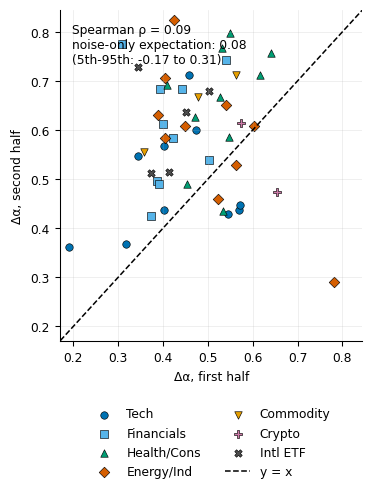

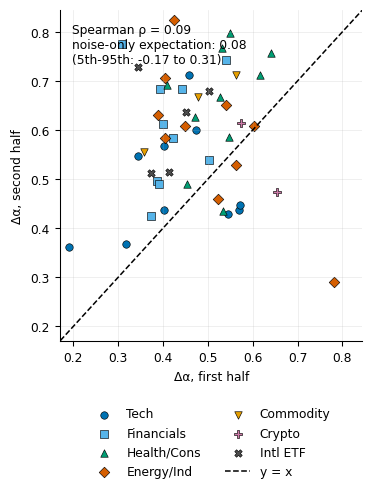

In [31]:
# ═════════ REVISION item 9: half-sample stability, noise vs true instability ═════════
# (i) both halves with the SAME maximum scale (cap from the shorter half);  (ii) split-half reliability of series whose true width is identical in
# both halves: whole-series shuffles (marginal kept, order destroyed) split in two -> the Spearman rho expected from sampling noise alone.
N_REL = int(os.environ.get("FLR_N_REL", 50))
def half_task(ticker, x, B, cfg):
    rng = np.random.default_rng(np.random.SeedSequence([cfg["SEED"], zlib.crc32(("half_" + ticker).encode())]))
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS", "SCALE_MIN", "SCALE_MAX", "N_SCALES", "POLY_ORD", "OVERLAP"))
    m = len(x) // 2; cap = min(smax, m // 4)
    def w(z): return delta_alpha(q, mfdfa_fast(z, q, smin, cap, ns, po, ov)[2])
    obs = (w(x[:m]), w(x[m:])); sh = np.array([(w(z[:m]), w(z[m:])) for z in (rng.permutation(x) for _ in range(B))])
    return ticker, obs, sh, cap, (len(x) - m) // 4
with timed("half-sample reliability"):
    hs = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(half_task)(t, returns_A[t].values, N_REL, CFG) for t in TICKERS_A)
obs_same = pd.DataFrame({t: o for t, o, _, _, _ in hs}, index=["first_half", "second_half"]).T.loc[TICKERS_A]
rho_same = stats.spearmanr(obs_same.first_half, obs_same.second_half, nan_policy="omit")[0]
unequal = [t for t, _, _, cap, cap2 in hs if cap != min(CFG["SCALE_MAX"], cap2)]
SH = np.stack([s for _, _, s, _, _ in hs])                                  # assets x B x 2
rho_b = np.array([stats.spearmanr(SH[:, b, 0], SH[:, b, 1], nan_policy="omit")[0] for b in range(N_REL)])
sb = lambda r: 2 * r / (1 + r)                                              # Spearman-Brown: reliability of the full-length estimate
noise = dict(observed_rho_original=float(rho), observed_rho_same_max_scale=float(rho_same), noise_rho_mean=float(rho_b.mean()), noise_rho_p05=float(np.percentile(rho_b, 5)),
             noise_rho_p95=float(np.percentile(rho_b, 95)), noise_rho_SB_mean=float(sb(rho_b.mean())), share_of_noise_draws_below_observed=float((rho_b <= rho_same).mean()), n_shuffles=N_REL)
rev_table(pd.Series(noise, name="value").to_frame(), "half_sample_noise_benchmark.csv"); rev_table(obs_same, "half_sample_same_max_scale.csv")
print("Half-sample stability:"); [print(f"  {k}: {v:.3f}" if isinstance(v, float) else f"  {k}: {v}") for k, v in noise.items()]
print(f"  assets whose two halves would have different max-scale caps under the old code: {unequal or 'none'} (halves differ by at most one observation)")
print("  Reading: under exchangeable halves (shuffled, same marginal) rho is expected near noise_rho_mean; a lower observed rho = non-stationarity beyond estimation noise.")
log_change("9", "half-sample Spearman rho (same max scale in both halves)", 0.09, float(rho_same))
log_change("9", "expected half-sample rho from noise alone (shuffled series, mean)", np.nan, float(rho_b.mean()))

# ── Fig. A.2: half-sample stability ──
def plot_half_sample(name="figA2_half_sample_stability"):
    fig, ax = plt.subplots(figsize=(FIG_W_1COL, 3.9))
    for g in GROUP_ORDER:
        d = stab[stab["group"] == g]; ax.scatter(d["first_half"], d["second_half"], c=CLASS_COLORS[g], marker=GROUP_MARKERS[g], edgecolor="k", lw=.4, s=24, label=g)
    lim = [np.nanmin(stab[["first_half", "second_half"]].values) - .02, np.nanmax(stab[["first_half", "second_half"]].values) + .02]
    ax.plot(lim, lim, "k--", lw=1, label="y = x"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Δα, first half"); ax.set_ylabel("Δα, second half")
    ax.text(.04, .96, f"Spearman ρ = {rho:.2f}\nnoise-only expectation: {noise['noise_rho_mean']:.2f}\n(5th-95th: {noise['noise_rho_p05']:.2f} to {noise['noise_rho_p95']:.2f})", transform=ax.transAxes, va="top")
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.17), ncol=2, frameon=False); savefig(fig, name); return fig
plot_half_sample()


In [32]:
# ═════════ REVISION item 12: rolling width vs correlation, horizon mismatch and power ═════════
# Cases per window length W: (1) overlapping step-20 windows, 60 d correlation (Table 2);  (2) overlapping, correlation averaged over the SAME window as the width
# (mean of the 60 d correlation series over the last W-59 days, so every 60 d window lies inside the width window);  (3)/(4) the same with NON-overlapping windows.
# Circular-shift permutation test as before (exact enumeration of all non-zero shifts when n < 30); effective n from lag-1 autocorrelations;
# vol-controlled rho gets a circular block-bootstrap CI (block = number of overlapped windows).
def _partial(a, c, v): return np.corrcoef(_resid(_rk(a), _rk(v)), _resid(_rk(c), _rk(v)))[0, 1]
def _perm_p(a, b, obs, n_perm, rng, corr_fn):
    n = len(a); ks = np.arange(1, n) if n < 30 else rng.integers(max(n // 10, 1), n - max(n // 10, 1), n_perm)
    null = np.array([corr_fn(a, np.roll(b, k)) for k in ks]); return (np.sum(np.abs(null) >= abs(obs)) + 1) / (len(null) + 1)
def _neff(a, b):
    r = lambda z: np.corrcoef(z[:-1], z[1:])[0, 1]; rr = r(_rk(a)) * r(_rk(b)); return len(a) * (1 - rr) / (1 + rr)
def _boot_partial(a, c, v, block, B, rng):
    n = len(a); nb = int(np.ceil(n / block)); out = np.empty(B)
    for i in range(B):
        idx = ((rng.integers(0, n, nb)[:, None] + np.arange(block)) % n).ravel()[:n]; out[i] = _partial(a[idx], c[idx], v[idx])
    return np.percentile(out, [2.5, 97.5])
rows_m = []; step = CFG["ROLL_STEP"]
with timed("window-matched rolling tests"):
    for Wn in WINDOWS:
        cm = corr60.rolling(Wn - WC + 1).mean()
        s_no = rolling_da(sp.values, sp.index, Wn, Wn)
        for case, sw, cs, blk in ((f"overlap, 60 d corr", series[Wn], corr60, int(np.ceil(Wn / step))), ("overlap, window-matched corr", series[Wn], cm, int(np.ceil(Wn / step))),
                                  ("non-overlap, 60 d corr", s_no, corr60, 1), ("non-overlap, window-matched corr", s_no, cm, 1)):
            d = pd.DataFrame({"da": sw, "corr": cs.reindex(sw.index), "vol": vol60.reindex(sw.index)}).dropna(); n = len(d)
            if n < 6: rows_m.append(dict(window=Wn, case=case, n_windows=n)); continue
            a, c, v = d.da.values, d["corr"].values, d.vol.values
            rr_raw = np.corrcoef(_rk(a), _rk(c))[0, 1]; p_raw = _perm_p(_rk(a), _rk(c), rr_raw, CFG["N_PERM"], rng_for(f"rev_w{Wn}_{case}_raw"), lambda x, y: np.corrcoef(x, y)[0, 1])
            pa_, pc_ = _resid(_rk(a), _rk(v)), _resid(_rk(c), _rk(v)); rr_par = np.corrcoef(pa_, pc_)[0, 1]
            p_par = _perm_p(pa_, pc_, rr_par, CFG["N_PERM"], rng_for(f"rev_w{Wn}_{case}_par"), lambda x, y: np.corrcoef(x, y)[0, 1])
            ci = _boot_partial(a, c, v, blk, CFG["N_BOOT"] * 2, rng_for(f"rev_boot_w{Wn}_{case}")) if n >= 12 else (np.nan, np.nan)
            rows_m.append(dict(window=Wn, case=case, n_windows=n, n_eff_autocorr=_neff(a, c), n_independent_nonoverlap=len(sp) // Wn, rho_raw=rr_raw, p_raw=p_raw,
                               rho_vol_controlled=rr_par, p_vol_controlled=p_par, rho_vol_ci_lo=ci[0], rho_vol_ci_hi=ci[1]))
matched = pd.DataFrame(rows_m); rev_table(matched, "rolling_window_matched.csv", index=False)
print("Rolling width vs correlation, horizon-matched and non-overlapping versions:"); print(matched.round(3).to_string(index=False))
print("\nTable 2 reference (overlap, 60 d corr; different permutation stream):"); print(sens.round(3).to_string())
log_change("12", "n independent windows (non-overlapping), 1000 d", np.nan, float(len(sp) // 1000))


[window-matched rolling tests] 7.3 s
Rolling width vs correlation, horizon-matched and non-overlapping versions:
 window                             case  n_windows  n_eff_autocorr  n_independent_nonoverlap  rho_raw  p_raw  rho_vol_controlled  p_vol_controlled  rho_vol_ci_lo  rho_vol_ci_hi
    750               overlap, 60 d corr        256          39.035                       7.0    0.094  0.727               0.287             0.549         -0.114          0.534
    750     overlap, window-matched corr        256          18.188                       7.0    0.248  0.709               0.268             0.638         -0.141          0.564
    750           non-overlap, 60 d corr          7           7.420                       7.0   -0.357  0.714               0.235             0.857            NaN            NaN
    750 non-overlap, window-matched corr          7          10.862                       7.0    0.107  0.857               0.698             0.286            NaN            N

In [33]:
# ═════════ REVISION items 15, 16, 18: number consistency ═════════
# ── 15: Table 1 deltas: point estimates vs bootstrap means ──
pairs = ((labs[0], labs[1]), (labs[1], labs[2])); rows_t = []
for a, b in pairs:
    dboot = boots[b] - boots[a]
    rows_t.append(dict(contrast=f"{b} minus {a}", point_difference=snap.loc[b, "mean_corr"] - snap.loc[a, "mean_corr"], bootstrap_mean_difference=dboot.mean(),
                       ci_lo=np.percentile(dboot, 2.5), ci_hi=np.percentile(dboot, 97.5), mean_level_a_point=snap.loc[a, "mean_corr"], mean_level_a_bootstrap=boots[a].mean(),
                       mean_level_b_point=snap.loc[b, "mean_corr"], mean_level_b_bootstrap=boots[b].mean()))
deltas = pd.DataFrame(rows_t); rev_table(deltas, "correlation_snapshot_deltas.csv", index=False); print(deltas.round(4).T.to_string())
print("-> section 6 printed the BOOTSTRAP-mean differences (d.mean()); the point estimates are the differences of unrounded sample means. Report one set and footnote the other, e.g.:")
fn15 = (f"Changes are point estimates from unrounded snapshot means ({deltas.point_difference.iloc[0]:+.3f}, {deltas.point_difference.iloc[1]:+.3f}); the bootstrap means of the differences are "
        f"{deltas.bootstrap_mean_difference.iloc[0]:+.3f} and {deltas.bootstrap_mean_difference.iloc[1]:+.3f}; brackets are percentile 95% intervals of the bootstrap differences "
        f"(circular block bootstrap, block = {CFG['BOOT_BLOCK']}, B = {CFG['N_BOOT']}).")
(REV / "tables" / "table1_footnote.txt").write_text(fn15); print(fn15)
log_change("15", "Table 1 delta 2006->2007 (bootstrap mean -> point estimate)", 0.308, float(deltas.point_difference.iloc[0]))
log_change("15", "Table 1 delta 2007->2008 (bootstrap mean -> point estimate)", 0.037, float(deltas.point_difference.iloc[1]))

# ── 16: exact definition of the shares ──
V4 = pd.DataFrame({"PR": res["phase_mean"], "SH-PR": res["shuffle_mean"] - res["phase_mean"], "IA-SH": res["iaaft_mean"] - res["shuffle_mean"], "obs-IA": res["delta_alpha"] - res["iaaft_mean"]})
ratio_of_sums = 100 * V4.sum() / res["delta_alpha"].sum()
mean_of_ratios = (100 * V4.div(res["delta_alpha"], axis=0)).mean(); median_of_ratios = (100 * V4.div(res["delta_alpha"], axis=0)).median()
sh_def = pd.DataFrame({"ratio of sums (paper, aggregate)": ratio_of_sums, "mean of per-asset ratios": mean_of_ratios, "median of per-asset ratios": median_of_ratios}); sh_def.loc["sum"] = sh_def.sum()
rev_table(sh_def, "share_definitions.csv"); print(sh_def.round(2).to_string())
print(f"PR share check: unrounded {100 * res.phase_mean.sum() / res.delta_alpha.sum():.3f}% ; from rounded means 0.231/0.548 = {100 * 0.231 / 0.548:.2f}% ; aggregate shares sum to {ratio_of_sums.sum():.6f}%")
print("Definition for the text: share_k = 100 * sum_i contrast_k,i / sum_i width_i (a ratio of cross-asset sums = width-weighted average of per-asset shares); "
      "the mean of per-asset ratios is a different statistic. The by-class stacked bars clip negative components to 0 and renormalize, so they can differ from the tables.")
log_change("16", "PR share of aggregate width (%)", 42.1, float(ratio_of_sums["PR"]))

# ── 18: cross-check against the earlier paper (values quoted by the author: Shetty et al., Zenodo 10.5281/zenodo.22804919) ──
EARLIER_HEADLINES = {"mean_shuffled_width": 0.374, "n_sig_shuffle_BH": 36, "KO_width": 0.824, "NVDA_width": 0.181, "GC=F_width": 0.5350}
mine = {"mean_shuffled_width": res["shuffle_mean"].mean(), "n_sig_shuffle_BH": int((res["q_shuffle"] < .05).sum()), "KO_width": res.loc["KO", "delta_alpha"],
        "NVDA_width": res.loc["NVDA", "delta_alpha"], "GC=F_width": res.loc["GC=F", "delta_alpha"]}
tol = {"mean_shuffled_width": 0.002, "n_sig_shuffle_BH": 0, "KO_width": 0.001, "NVDA_width": 0.001, "GC=F_width": 0.001}
xc = pd.DataFrame({"this code": mine, "earlier paper": EARLIER_HEADLINES}); xc["abs diff"] = (xc["this code"] - xc["earlier paper"]).abs(); xc["flag"] = [("DIFFERS" if xc.loc[k, "abs diff"] > tol[k] else "ok") for k in xc.index]
rev_table(xc, "crosscheck_earlier_paper_headlines.csv"); print(xc.round(4).to_string())
_ep = os.environ.get("FLR_EARLIER_TABLE")        # optional CSV with columns: ticker,width,shuffled_width  (the earlier paper's Table 1)
if _ep and Path(_ep).exists():
    et = pd.read_csv(_ep).set_index("ticker"); cmpt = pd.DataFrame({"width_this": res["delta_alpha"], "width_earlier": et["width"], "shuffled_this": res["shuffle_mean"], "shuffled_earlier": et["shuffled_width"]}).dropna()
    cmpt["d_width"] = cmpt.width_this - cmpt.width_earlier; cmpt["d_shuffled"] = cmpt.shuffled_this - cmpt.shuffled_earlier; cmpt["flag"] = np.where((cmpt.d_width.abs() > .001) | (cmpt.d_shuffled.abs() > .002), "DIFFERS", "ok")
    rev_table(cmpt, "crosscheck_earlier_paper_per_asset.csv"); print(cmpt.round(4).to_string()); print(f"{int((cmpt.flag == 'DIFFERS').sum())} of {len(cmpt)} assets differ")
else:
    print("Per-asset comparison skipped: set FLR_EARLIER_TABLE=/path/to/earlier_table1.csv (columns ticker,width,shuffled_width) to enable it.")


                                                                               0                                                        1
contrast                   Pre-crash peak (Oct 2007) minus Pre-bubble (Jan 2006)  During crash (Oct 2008) minus Pre-crash peak (Oct 2007)
point_difference                                                          0.3051                                                   0.0405
bootstrap_mean_difference                                                  0.308                                                   0.0371
ci_lo                                                                     0.1746                                                  -0.1124
ci_hi                                                                     0.4379                                                   0.1789
mean_level_a_point                                                        0.2299                                                    0.535
mean_level_a_bootstrap            

[Fig. 1] GC=F: width = 0.5291 | tau(0) = -1.0000 | f(alpha) max = 1.0652 at q = +0
[Fig. 1] WARNING: f(alpha) peak exceeds 1 (1.0652); data not clipped. See spectrum_fmax_check.csv for the cause (smoothing / non-concave tau).
[Fig. 1] width here 0.5291 vs earlier paper 0.5350  <-- WARNING: differ by more than 0.001


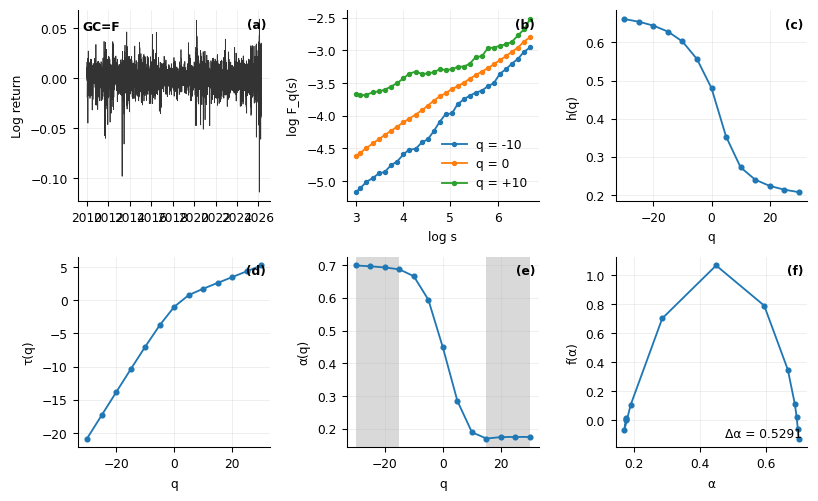

In [34]:
# ═════════ REVISION item 21 / Task 2, Fig. 1: single-asset MF-DFA panel (asset given by FLR_FIG1_ASSET, default GC=F) ═════════
# NOTE: the original script of this figure was not part of the notebook; this is a reconstruction with the six panels described in the task
# (a) log-returns, (b) F_q(s) scaling, (c) h(q), (d) tau(q), (e) alpha(q), (f) f(alpha). Check the layout against your earlier figure.
FIG1_ASSET = os.environ.get("FLR_FIG1_ASSET", "GC=F")
EARLIER_PAPER_WIDTHS = {"GC=F": 0.5350}          # width quoted by the author from the earlier paper's Table 1
def single_asset_figure(t, name="fig1_single_asset"):
    x = returns_A[t].values; q = np.array(CFG["Q_VALS"]); scales, Fq, hq = mfdfa_fast(x, q, CFG["SCALE_MIN"], CFG["SCALE_MAX"], CFG["N_SCALES"], CFG["POLY_ORD"], CFG["OVERLAP"])
    tau, alpha, f = spectrum(q, hq); w = delta_alpha(q, hq); i0 = int(np.where(q == 0)[0][0])
    print(f"[Fig. 1] {t}: width = {w:.4f} | tau(0) = {tau[i0]:+.4f} | f(alpha) max = {np.nanmax(f):.4f} at q = {q[int(np.nanargmax(f))]:+.0f}")
    if np.nanmax(f) > 1 + 1e-9: print(f"[Fig. 1] WARNING: f(alpha) peak exceeds 1 ({np.nanmax(f):.4f}); data not clipped. See spectrum_fmax_check.csv for the cause (smoothing / non-concave tau).")
    if t in EARLIER_PAPER_WIDTHS:
        dd = abs(w - EARLIER_PAPER_WIDTHS[t]); print(f"[Fig. 1] width here {w:.4f} vs earlier paper {EARLIER_PAPER_WIDTHS[t]:.4f}" + ("  <-- WARNING: differ by more than 0.001" if dd > 1e-3 else "  (agree within 0.001)"))
    slope = np.abs(np.gradient(alpha, q)); thr = .1 * slope.max()                       # "flat" where |d alpha/dq| < 10% of its maximum, beyond which it stays flat
    def flat_from(side):
        idx = np.where(side)[0]; idx = idx[np.argsort(np.abs(q[idx]))]
        for j, i in enumerate(idx):
            if np.all(slope[idx[j:]] <= thr): return abs(q[i])
        return None
    qp, qn = flat_from(q > 0), flat_from(q < 0)
    fig, axs = plt.subplots(2, 3, figsize=(FIG_W_2COL, 4.6)); a = axs.ravel()
    a[0].plot(returns_A[t].index, x, lw=.5, c="0.2"); a[0].set_ylabel("Log return"); a[0].text(.02, .95, f"{t}", transform=a[0].transAxes, va="top", fontweight="bold")
    for qq in (-10, 0, 10):
        j = int(np.where(q == qq)[0][0]); a[1].plot(np.log(scales), np.log(Fq[j]), marker="o", ms=2.5, label=f"q = {qq:+d}".replace("+0", "0"))
    a[1].set_xlabel("log s"); a[1].set_ylabel("log F_q(s)"); a[1].legend(frameon=False)
    a[2].plot(q, hq, "o-", ms=3); a[2].set_xlabel("q"); a[2].set_ylabel("h(q)")
    a[3].plot(q, tau, "o-", ms=3); a[3].set_xlabel("q"); a[3].set_ylabel("τ(q)")
    a[4].plot(q, alpha, "o-", ms=3); a[4].set_xlabel("q"); a[4].set_ylabel("α(q)")
    if qp is not None: a[4].axvspan(qp, q.max(), color="0.85", lw=0)
    if qn is not None: a[4].axvspan(q.min(), -qn, color="0.85", lw=0)
    a[5].plot(alpha, f, "o-", ms=3); a[5].set_xlabel("α"); a[5].set_ylabel("f(α)")
    a[5].text(.97, .05, f"Δα = {w:.4f}", transform=a[5].transAxes, ha="right")
    for k, ax_ in enumerate(a): ax_.text(.98, .96, f"({'abcdef'[k]})", transform=ax_.transAxes, va="top", ha="right", fontweight="bold")
    fig.tight_layout(); savefig(fig, name)
    (REV / "tables" / "fig1_caption.txt").write_text(f"Single-asset MF-DFA for {t}: (a) log returns, (b) fluctuation functions, (c) h(q), (d) tau(q), (e) alpha(q) (shaded: region where alpha is flat, "
                                                    f"defined from the data as |d alpha/dq| below 10% of its maximum), (f) f(alpha). Width = {w:.4f}.\n")
single_asset_figure(FIG1_ASSET)


In [36]:
# ═════════ REVISION: change log, suggested text, release files ═════════
def _chg(o, n):
    try: return (not np.isfinite(float(o))) or abs(float(o) - float(n)) > 5e-4
    except Exception: return True
chg = pd.DataFrame(CHANGES); chg["changed"] = [_chg(o, n) for o, n in zip(chg.old, chg.new)]
chg.to_csv(REV / "change_log.csv", index=False); print("CHANGE LOG (old = previous run's saved outputs; new = this run):"); print(chg.to_string(index=False))

g = lambda n, N: float(bench.query(f"benchmark=='{n}' and N=={N}").mean_width.iloc[0])
a_, b_, c_ = clf.iloc[0], (clf.iloc[1] if len(clf) > 2 else clf.iloc[0]), clf.iloc[-1]
sh = order_summaries["full"]
txt = f"""# Suggested replacement text (numbers are filled from this run; check each before pasting)

## Section 2, CL=F handling
Non-positive prices are removed before log returns are computed. For WTI crude (CL=F), the settlement of {info.get('negative_price', float('nan')):.2f} on {info.get('negative_price_date', 'n/a')} is dropped, so one return ({info.get('spanning_return_from', 'n/a')} to {info.get('spanning_return_to', 'n/a')}, {info.get('spanning_return_value', float('nan')):+.3f}) spans two trading days; CL=F has {info['n_returns_as_implemented']} returns. Dropping that return changes the CL=F width from {a_.width_CLF:.3f} to {b_.width_CLF:.3f}; excluding CL=F changes the commodity COVID-deletion change from {a_.covid_change_commodities:+.3f} to {c_.covid_change_commodities:+.3f} (mean width over all assets {a_.mean_width_all:.3f} vs {c_.mean_width_all:.3f}).

## Section 2, sampling
Equities and ETFs use trading-day returns ({modal} returns for {int((audit.n_returns == modal).sum())} of {len(audit)} assets); the exceptions are {', '.join(exc.index)}. Crypto series are sampled on all seven days of the week (BTC-USD starts {audit.loc['BTC-USD','first_return']}, ETH-USD {audit.loc['ETH-USD','first_return']}, when Yahoo history begins). Data end on {end_chk.last_return_equities} (the download end date {CFG['END_A']} is exclusive). The 40 equities cover {int((gics_cnt > 0).sum())} of the 11 GICS sectors (no {', '.join(s for s in ALL11 if gics_cnt[s] == 0)}); counts: {', '.join(f'{k} {v}' for k, v in gics_cnt[gics_cnt > 0].items())}.

## Section 3.5, block lengths and the benchmark
Episode lengths in the simulation are trading days: the 2020 window ({EPISODES_D['COVID'][0]} to {EPISODES_D['COVID'][1]}) contains {COVID_TD} trading days ({COVID_CAL} calendar days) and the 2008-09 window ({EPISODES_D['GFC'][0]} to {EPISODES_D['GFC'][1]}) {GFC_TD} ({GFC_CAL} calendar days). The mean width of i.i.d. Gaussian series is {g('i.i.d. Gaussian', 4091):.3f} (N = 4,091) and {g('i.i.d. Gaussian', 4600):.3f} (N = 4,600; B = {B_G}), compared with {g('i.i.d. Student-t(4)', 4600):.3f} for i.i.d. Student-t(4) at N = 4,600 and {pr_main:.3f} for the phase-randomized surrogates of the observed series. The phase-randomized mean preserves each asset's linear spectrum and is therefore not an i.i.d. Gaussian floor. Block position and length explain the two COVID-length x6 values ({diag.iloc[0,0]:+.3f} random position, L = 133; {diag.iloc[2,0]:+.3f} fixed late position, L = 132).

## Figure captions
Fig. 1: see tables/fig1_caption.txt.  Fig. 4: Shares are descriptive and depend on the order of the steps: across the six orderings that end at the observed width, the share of the SH step ranges from {sh.loc['SH','min over 6 orders (%)']:.1f}% to {sh.loc['SH','max over 6 orders (%)']:.1f}% (full sample). Brackets: 95% percentile bootstrap intervals of each share over assets (2,000 resamples); they do not include surrogate Monte Carlo error.
Fig. 5: n = 150 placebo windows; the minimum attainable p-value is 1/151.  Fig. 6: see tables/fig6_caption_numbers.txt.  Fig. 7: see tables/fig7_caption.txt.
Table 1 footnote: see tables/table1_footnote.txt.  Table 3 caption: see tables/scaling_variance_ratio_caption.txt.

## Data and code availability (fill the bracketed items after the upload)
Code, the frozen configuration (SHA-256 prefix {CFG_HASH}), the data manifest (SHA-256 of every cached price file; digest {meta['data_manifest_sha256'][:16]}), seeds (master seed {CFG['SEED']}) and run metadata are available at [REPOSITORY URL] and archived at Zenodo [DOI]. Prices are Yahoo Finance auto-adjusted closes retrieved with yfinance on the dates recorded in the manifest.
"""
(REV / "suggested_text.md").write_text(txt, encoding="utf-8"); print("\nwritten:", REV / "suggested_text.md")
revnums = dict(iid_benchmark=bench.round(4).to_dict("records"), clf=clf.round(4).to_dict("records"), covid_td=COVID_TD, gfc_td=GFC_TD,
               half_sample=noise, order_dependence={k: v.round(3).to_dict() for k, v in order_summaries.items()},
               vr_adjusted=scal[["index", "horizon_days", "p_value", "p_BH", "p_Holm"]].round(4).to_dict("records"), fig6=fig6_numbers)
(REV / "paper_revision_numbers.json").write_text(json.dumps(revnums, indent=1, default=str), encoding="utf-8")

print("Files in", REV, ":")
for p in sorted(REV.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(REV))

CHANGE LOG (old = previous run's saved outputs; new = this run):
item                                                                                         quantity                      old                      new  changed
  10 COVID-length block (×6): change in Δα (random position) [old L=133 calendar -> new L=93 trading]                    0.178                 0.214502     True
  10                                     COVID-only (fixed late position, ×6) [old L=132 -> new L=93]                    0.189                 0.217293     True
  10                                                           GFC-only (×3) [old L=302 -> new L=209]                    0.059                 0.077075     True
   1                                                           i.i.d. Student-t(4) mean width, N=4600                    0.352                 0.348039     True
   1                                                         i.i.d. Gaussian mean width, N=4091 (new)                      NaN    